In [46]:
# Esegui le celle dall'alto verso il basso: quelle successive usano le variabili create prima.
# Il kernel è il processo che esegue Python e conserva queste variabili in memoria.
# Le righe che iniziano con # sono commenti: servono a spiegare e non vengono eseguite.
# OBIETTIVO: preparare gli strumenti necessari per leggere dati, addestrare modelli e disegnare grafici.
# Una libreria è un insieme di funzioni già pronte. 'import' le rende utilizzabili nel notebook.
# Path permette di rappresentare percorsi di file e verificare, per esempio, se il CSV esiste.
from pathlib import Path

# pandas gestisce tabelle di dati: ogni riga sarà una prenotazione e ogni colonna una sua caratteristica.
# 'as pd' assegna un nome breve alla libreria, che useremo in istruzioni come pd.read_csv(...).
import pandas as pd
# matplotlib crea figure, assi, titoli e grafici. Lo richiamiamo con il nome breve plt.
import matplotlib.pyplot as plt
# seaborn, abbreviato sns, aggiunge stili e grafici statistici come la matrice colorata degli errori.
import seaborn as sns

# scikit-learn fornisce gli strumenti di machine learning, cioè di apprendimento dai dati.
# clone crea un modello nuovo con le stesse impostazioni, senza copiare ciò che ha già imparato.
from sklearn.base import clone
# ColumnTransformer applica preparazioni diverse a colonne numeriche e colonne contenenti categorie.
from sklearn.compose import ColumnTransformer
# DummyClassifier fornisce un riferimento semplice: qui indovinerà sempre la classe più frequente.
from sklearn.dummy import DummyClassifier
# SimpleImputer riempie i valori mancanti usando una regola imparata dai dati di addestramento.
from sklearn.impute import SimpleImputer
# La regressione logistica stima la probabilità di una classe: qui cancellata oppure non cancellata.
# Nonostante il nome 'regressione', in questo notebook viene usata per classificare.
from sklearn.linear_model import LogisticRegression
# Le metriche sono numeri con cui valutiamo le previsioni: correttezza, errori e capacità di distinguere le classi.
# classification_report riassume più metriche; confusion_matrix conta i diversi tipi di esito.
# roc_curve e roc_auc_score valutano le probabilità al variare della soglia di decisione.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
# train_test_split separa dati per imparare e dati per verificare il risultato.
# StratifiedKFold e cross_validate ripetono la valutazione su più suddivisioni del solo training set.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
# Pipeline collega più passaggi in ordine, per esempio: riempi mancanti, trasforma colonne, addestra.
from sklearn.pipeline import Pipeline
# StandardScaler mette le variabili numeriche su scale confrontabili.
# OneHotEncoder traduce categorie come 'City Hotel' in colonne di indicatori 0/1.
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# print mostra un messaggio nell'output della cella; non addestra ancora alcun modello.
print("Librerie importate correttamente.")

Librerie importate correttamente.


In [47]:
# OBIETTIVO: caricare la tabella delle prenotazioni e ricavarne un campione più rapido da elaborare.
# Un CSV è un file di testo che rappresenta una tabella: la prima riga contiene i nomi delle colonne.
# Se il file esiste nella cartella, non serve la connessione Internet.
# Questo percorso relativo cerca hotels.csv nella cartella di lavoro corrente del notebook.
file_locale = Path("hotels.csv")
# Se il file locale manca, questo indirizzo indica dove scaricare il dataset pubblico.
# Python unisce automaticamente le due stringhe racchiuse nelle parentesi.
fonte_csv = (
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
    "main/data/2020/2020-02-11/hotels.csv"
)

# if significa 'se': il primo ramo viene eseguito solo quando il file è già presente.
if file_locale.exists():
    # read_csv legge il file e restituisce un DataFrame, cioè una tabella pandas.
    # df_originale conserva l'intero dataset; più avanti useremo anche una sua selezione di righe.
    df_originale = pd.read_csv(file_locale)
    print("Dataset caricato dal file locale.")
# else significa 'altrimenti': questo ramo gestisce il caso in cui il CSV locale non sia disponibile.
else:
    print("File locale non trovato: download del dataset pubblico in corso...")
    # try prova a eseguire il download; except intercetta un eventuale errore, per esempio di connessione.
    try:
        df_originale = pd.read_csv(fonte_csv)
    # Conserviamo l'errore originale e mostriamo un messaggio con indicazioni per risolvere il problema.
    except Exception as errore:
        raise RuntimeError(
            "Non riesco a scaricare hotels.csv. Apri la fonte indicata nella "
            "documentazione, scarica il CSV e mettilo accanto al notebook."
        ) from errore
    # Salviamo una copia locale per le esecuzioni successive.
    # index=False evita di scrivere nel CSV anche i numeri di riga interni di pandas.
    df_originale.to_csv(file_locale, index=False)
    print("Dataset originale salvato come hotels.csv.")

# Campionamento casuale e riproducibile: NON altera i valori delle prenotazioni.
# sample estrae righe casuali, senza modificare i valori contenuti nelle prenotazioni.
# min(12000, len(...)) prende al massimo 12.000 righe e funziona anche con un dataset più piccolo.
# random_state=42 fissa la casualità: ripetendo l'operazione sugli stessi dati otteniamo lo stesso campione.
# reset_index(drop=True) rinumera le righe da zero senza aggiungere il vecchio indice come colonna.
df = df_originale.sample(
    n=min(12000, len(df_originale)), random_state=42
).reset_index(drop=True)

# shape[0] indica il numero di righe; shape[1] il numero di colonne.
# La f davanti a una stringa permette di inserire valori calcolati dentro le parentesi graffe.
print(f"Dataset completo: {df_originale.shape[0]} righe")
print(f"Campione per la lezione: {df.shape[0]} righe, {df.shape[1]} colonne")
# head(10) seleziona le prime dieci righe; display le mostra come tabella nel notebook.
display(df.head(10))

Dataset caricato dal file locale.
Dataset completo: 119390 righe
Campione per la lezione: 12000 righe, 32 colonne


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,No Deposit,250.0,NaN,0,Transient,66.80,0,0,Check-Out,2016-12-09
1,City Hotel,1,82,2015,July,29,16,0,3,2,...,No Deposit,9.0,NaN,0,Transient,76.50,0,0,Canceled,2015-07-16
2,City Hotel,0,25,2016,December,53,27,0,3,3,...,No Deposit,220.0,NaN,0,Transient-Party,60.00,0,1,Check-Out,2016-12-30
3,City Hotel,0,1,2016,March,11,9,0,1,1,...,No Deposit,9.0,NaN,0,Transient-Party,95.00,0,0,Check-Out,2016-03-10
4,City Hotel,0,70,2017,April,16,16,2,2,2,...,No Deposit,9.0,NaN,0,Transient,108.00,0,0,Check-Out,2017-04-20
5,City Hotel,0,170,2017,April,17,27,0,3,2,...,No Deposit,9.0,NaN,0,Transient,130.50,0,0,Check-Out,2017-04-30
6,City Hotel,1,21,2016,March,10,4,0,1,1,...,No Deposit,9.0,NaN,0,Transient-Party,85.00,0,0,Canceled,2016-02-26
7,City Hotel,0,102,2015,October,42,16,0,2,2,...,No Deposit,6.0,NaN,0,Transient-Party,109.00,0,0,Check-Out,2015-10-18
8,Resort Hotel,0,55,2016,November,47,19,2,5,2,...,No Deposit,314.0,NaN,0,Transient,67.44,0,0,Check-Out,2016-11-26
9,Resort Hotel,0,222,2015,September,38,14,1,1,2,...,No Deposit,68.0,NaN,0,Transient,80.00,0,0,Check-Out,2015-09-16


In [48]:
# OBIETTIVO: mostrare la distinzione tra informazioni di ingresso X e risposta da prevedere y.
# Questa è una selezione iniziale di esempio: la cella successiva ridefinisce X con più colonne.
# Le doppie parentesi quadre selezionano una tabella composta dalle quattro colonne elencate.
# lead_time è l’anticipo in giorni, adults il numero di adulti, hotel il tipo di hotel e market_segment il segmento di mercato.
X = df[["lead_time", "adults", "hotel", "market_segment"]]
# y è il target, cioè la risposta che il modello deve imparare a prevedere.
# is_canceled vale 1 per una prenotazione cancellata e 0 per una non cancellata.
y = df["is_canceled"]

In [49]:
# OBIETTIVO: preparare i dati, addestrare una regressione logistica e valutarne le previsioni.
# copy crea una tabella separata su cui lavorare, mantenendo disponibile anche il campione df.
dati = df.copy()

# Le caratteristiche, dette anche feature, sono le informazioni fornite al modello.
# Questa lista contiene quantità: giorni, notti, persone, conteggi e tariffa media.
# Il modello usa soltanto le colonne selezionate, non tutte quelle presenti nel CSV.
numeriche = [
    # Giorni tra la prenotazione e l'arrivo previsto.
    'lead_time',
    # Notti del soggiorno nel fine settimana.
    'stays_in_weekend_nights',
    # Notti del soggiorno nei giorni feriali.
    'stays_in_week_nights',
    # Numero di adulti inclusi nella prenotazione.
    'adults',
    # Numero di bambini inclusi nella prenotazione.
    'children',
    # Numero di neonati inclusi nella prenotazione.
    'babies',
    # Numero di precedenti prenotazioni cancellate dal cliente.
    'previous_cancellations',
    # Numero di precedenti prenotazioni del cliente non cancellate.
    'previous_bookings_not_canceled',
    # Numero di richieste speciali associate alla prenotazione.
    'total_of_special_requests',
    # Numero di posti auto richiesti dal cliente.
    'required_car_parking_spaces',
    # Average Daily Rate: tariffa media giornaliera della prenotazione.
    'adr',
]

# Le categorie sono etichette: un hotel o un paese non rappresentano una quantità da sommare.
# Anche il mese viene trattato come categoria, per rappresentare differenze stagionali.
# Per una previsione reale, ogni caratteristica deve essere già nota quando si effettua la previsione.
categoriche = [
    # Tipo di hotel, per esempio albergo di città oppure resort.
    'hotel',
    # Mese previsto di arrivo.
    'arrival_date_month',
    # Trattamento pasti prenotato, per esempio pernottamento e colazione.
    'meal',
    # Paese di provenienza del cliente.
    'country',
    # Segmento di mercato da cui proviene la prenotazione.
    'market_segment',
    # Categoria di camera prenotata, espressa con un codice.
    'reserved_room_type',
    # Tipologia di prenotazione o cliente, per esempio gruppo oppure individuale.
    'customer_type',
]

# Il simbolo + unisce le due liste di nomi: X contiene tutte le caratteristiche selezionate.
# Ogni riga di X descrive una prenotazione; y contiene la risposta reale della stessa riga.
# is_canceled resta fuori da X: includerlo significherebbe fornire direttamente la risposta.
X = dati[numeriche + categoriche]
# La classe positiva è 1, cioè 'Cancellata'; la classe 0 significa 'Non cancellata'.
y = dati["is_canceled"]

# Separiamo le righe prima di imparare qualsiasi trasformazione dai dati.
# Il training set serve per imparare; il test set è tenuto da parte per la valutazione finale.
# X e y vengono suddivisi insieme, mantenendo associati i dati di ogni prenotazione al suo esito.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    # Riserviamo il 20% delle righe al test e lasciamo l'80% all'addestramento.
    test_size=0.20,
    # Il seme fisso rende riproducibile la suddivisione sugli stessi dati.
    random_state=42,
    # Manteniamo nei due gruppi proporzioni simili di cancellazioni e non cancellazioni.
    stratify=y,
)

# Prepariamo le colonne numeriche con due operazioni, eseguite nell'ordine scritto.
# L'imputer sostituisce i mancanti con la media della colonna, calcolata sui soli dati di training.
# Lo scaler sottrae la media e divide per la deviazione standard: evita che la scala di una variabile domini le altre.
pipeline_numeriche = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])

# Per le categorie riempiamo i mancanti con il valore più frequente del training set.
# L'encoder crea una colonna 0/1 per ogni categoria: il classificatore può così elaborare numeri.
# handle_unknown='ignore' permette di gestire nel test categorie mai incontrate durante il training;
# per quella caratteristica, una categoria sconosciuta viene rappresentata da indicatori tutti a zero.
pipeline_categoriche = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# Il preprocessing è la preparazione dei dati prima del modello.
# ColumnTransformer applica ogni pipeline al proprio elenco di colonne, poi unisce i risultati.
# Le altre colonne del CSV non entrano nel modello perché non fanno parte di X.
preprocessing = ColumnTransformer([
    ("numeriche", pipeline_numeriche, numeriche),
    ("categoriche", pipeline_categoriche, categoriche),
])

# La pipeline completa prepara i dati e li passa al classificatore.
# Tenere la preparazione nella pipeline fa imparare medie, scale e categorie solo dai dati usati per fit.
# La regressione logistica combina le caratteristiche per stimare la probabilità di cancellazione.
# max_iter=2000 fissa il massimo numero di iterazioni del calcolo, non il numero di prenotazioni.
modello = Pipeline([
    ("preprocessing", preprocessing),
    ("classificatore", LogisticRegression(max_iter=2000)),
])

# fit significa addestrare: il modello confronta le caratteristiche X_train con le risposte y_train
# per imparare una relazione da usare su altre prenotazioni.
# Addestramento
modello.fit(X_train, y_train)

# predict applica al test le trasformazioni già imparate, poi restituisce una classe 0 oppure 1.
# Per questa classificazione binaria la decisione standard corrisponde a una soglia di circa 0,5.
# Previsioni sui dati mai visti
y_pred = modello.predict(X_test)

# La baseline è un riferimento minimo: verifica quanto si ottiene scegliendo sempre la classe più comune.
# Non usa le caratteristiche per distinguere le prenotazioni; conta quanto le classi siano sbilanciate.
# Confronto con un modello che predice sempre la classe più frequente
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Accuracy = numero di previsioni corrette / numero totale di prenotazioni valutate.
# Confrontiamo le previsioni con y_test, che contiene gli esiti reali e non viene usato per addestrare.
print("Accuracy baseline:", accuracy_score(y_test, baseline.predict(X_test)))
print("Accuracy modello:", accuracy_score(y_test, y_pred))

# Il report mostra una riga per ogni classe.
# Precision: tra le previsioni di una classe, quante sono corrette.
# Recall: tra i casi reali di una classe, quanti vengono individuati.
# F1: media armonica di precision e recall; diminuisce se una delle due è bassa.
# Support: numero di esempi reali di quella classe nel test.
# Macro avg dà lo stesso peso alle classi; weighted avg pesa ogni classe in base al suo support.
# zero_division=0 assegna zero alle metriche che non si possono calcolare per mancanza di casi.
print("\nReport di classificazione:")
print(classification_report(
    y_test, y_pred,
    target_names=["Non cancellata", "Cancellata"],
    zero_division=0,
))

# La matrice conta gli esiti: le righe sono le classi reali, le colonne quelle previste.
# Con ordine [0, 1]: in alto a sinistra troviamo le non cancellate corrette;
# in alto a destra le false cancellazioni; in basso a sinistra le cancellazioni non individuate;
# in basso a destra le cancellazioni corrette.
print("Matrice di confusione:")
print(confusion_matrix(y_test, y_pred))

Accuracy baseline: 0.6225
Accuracy modello: 0.81

Report di classificazione:
                precision    recall  f1-score   support

Non cancellata       0.82      0.89      0.85      1494
    Cancellata       0.79      0.67      0.73       906

      accuracy                           0.81      2400
     macro avg       0.81      0.78      0.79      2400
  weighted avg       0.81      0.81      0.81      2400

Matrice di confusione:
[[1335  159]
 [ 297  609]]


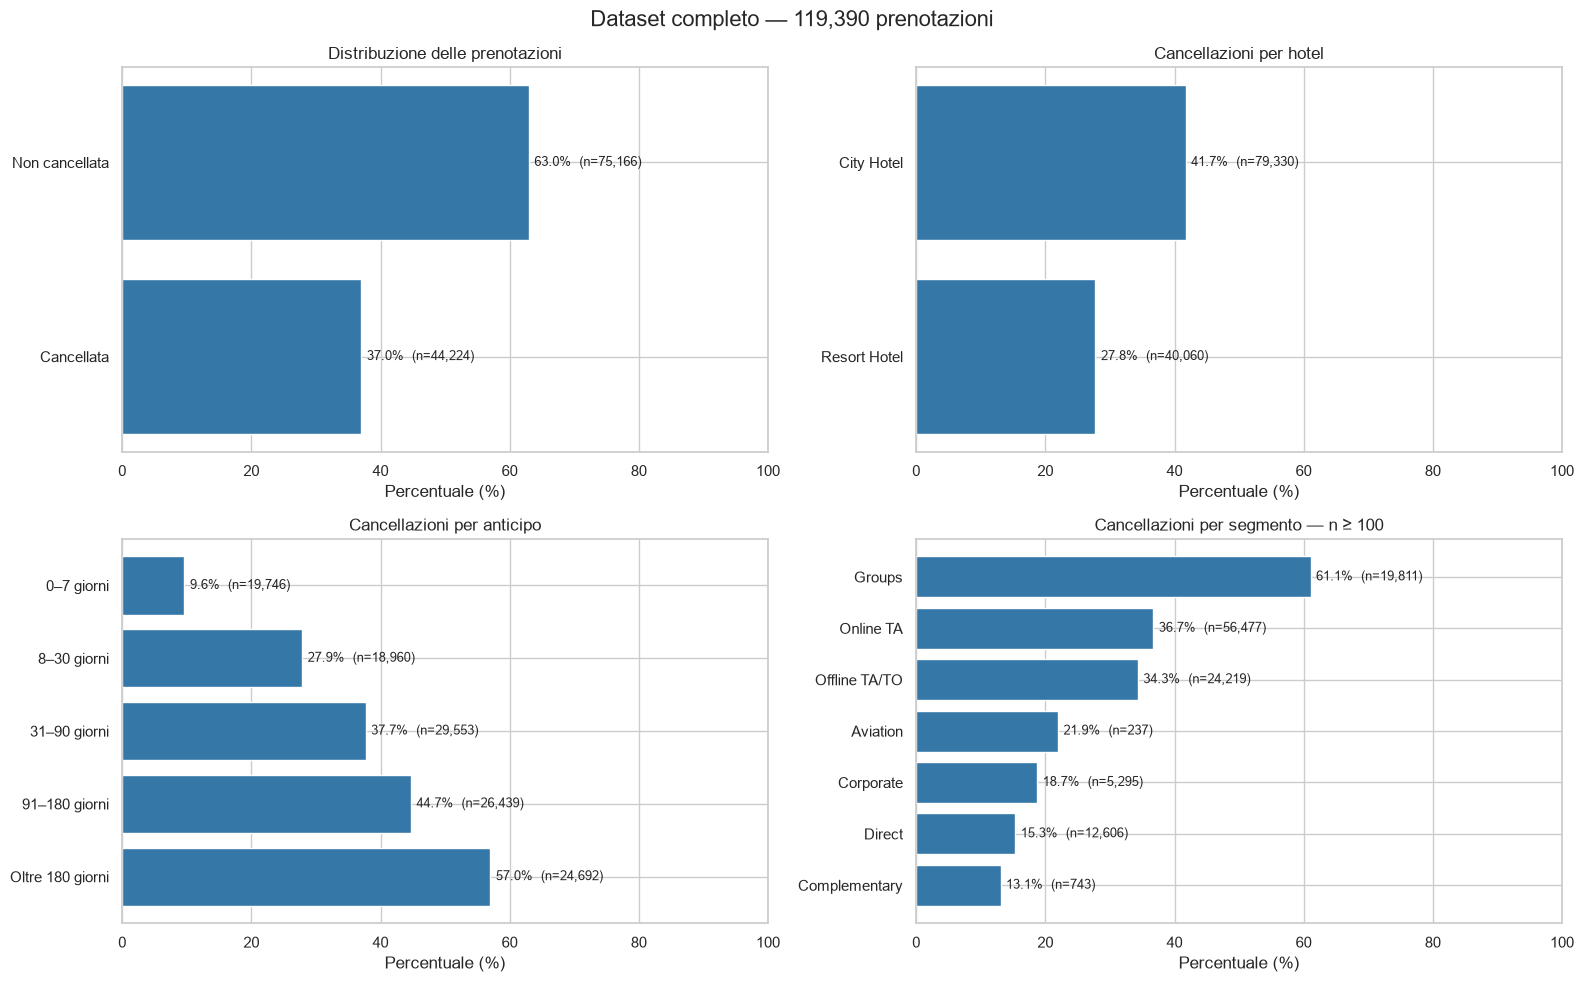

In [50]:
# Esploriamo i dati con quattro grafici: descrivono le prenotazioni osservate.
# Questa cella non addestra un modello: aiuta a vedere come variano le cancellazioni.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Impostiamo uno stile comune ai grafici, con una griglia chiara sullo sfondo.
sns.set_theme(style="whitegrid")

# Usiamo una copia del dataset completo, così le nuove colonne di analisi
# non vengono aggiunte alla tabella originale usata nelle altre celle.
base = df_originale.copy()
nome_base = "Dataset completo"

# Fasce di anticipo della prenotazione
# lead_time indica quanti giorni prima dell’arrivo è stata fatta la prenotazione.
# pd.cut raggruppa questi numeri in intervalli; bins fissa i confini e labels i nomi.
# Il primo confine -1 include anche 0 giorni; infinito include ogni anticipo oltre 180.
base["fascia_anticipo"] = pd.cut(
    base["lead_time"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=["0–7 giorni", "8–30 giorni", "31–90 giorni",
            "91–180 giorni", "Oltre 180 giorni"],
)

# Per una variabile binaria, la media è la proporzione di valori 1.
# Una funzione raccoglie istruzioni riutilizzabili: qui produciamo lo stesso
# riepilogo per hotel, fasce di anticipo e segmenti di mercato.
def riepilogo(colonna):
    # groupby divide le righe in gruppi con lo stesso valore della colonna.
    # observed=True mantiene solo le categorie effettivamente presenti nei dati.
    # agg calcola n (numero di prenotazioni) e tasso (media di is_canceled: 0 oppure 1).
    tabella = base.groupby(
        colonna, observed=True
    )["is_canceled"].agg(n="size", tasso="mean")

    # Convertiamo la proporzione in percentuale: ad esempio 0,30 diventa 30%.
    tabella["tasso"] *= 100
    # return restituisce il risultato a chi ha chiamato la funzione.
    return tabella

# Contiamo le due classi: 0 = non cancellata, 1 = cancellata.
# reindex le dispone in questo ordine e assegna 0 se una classe non è presente.
conteggi = base["is_canceled"].value_counts().reindex([0, 1], fill_value=0)

# Costruiamo una tabella con conteggi e percentuali sul totale delle prenotazioni.
# rename sostituisce i codici 0 e 1 con etichette leggibili.
distribuzione = pd.DataFrame({
    "n": conteggi,
    "tasso": conteggi / len(base) * 100,
}).rename(index={0: "Non cancellata", 1: "Cancellata"})

# Nei prossimi riepiloghi la percentuale è il tasso di cancellazione DENTRO ogni
# gruppo: per esempio, cancellazioni di un hotel divise per tutte le sue prenotazioni.
hotel = riepilogo("hotel")
anticipo = riepilogo("fascia_anticipo")

# Filtro di visualizzazione: mostriamo segmenti con almeno 100 righe.
segmenti = riepilogo("market_segment")
# loc seleziona i gruppi abbastanza numerosi per questo grafico; sort_values
# li ordina dal tasso maggiore al minore. Le altre righe del dataset restano disponibili.
segmenti = segmenti.loc[segmenti["n"] >= 100].sort_values(
    "tasso", ascending=False
)

# Abbiniamo ogni tabella al titolo del suo grafico, così possiamo disegnarli
# tutti con lo stesso ciclo senza ripetere quattro volte le istruzioni.
grafici = [
    (distribuzione, "Distribuzione delle prenotazioni"),
    (hotel, "Cancellazioni per hotel"),
    (anticipo, "Cancellazioni per anticipo"),
    (segmenti, "Cancellazioni per segmento — n ≥ 100"),
]

# fig è la figura complessiva; assi contiene i quattro riquadri (2 righe e 2 colonne).
# figsize stabilisce larghezza e altezza della figura in pollici.
fig, assi = plt.subplots(2, 2, figsize=(16, 10))

# flat permette di visitare i riquadri uno alla volta; zip abbina ciascun
# riquadro alla relativa tabella e al relativo titolo.
for ax, (tabella, titolo) in zip(assi.flat, grafici):
    # barh disegna barre orizzontali: le categorie sono sull’asse verticale,
    # mentre la lunghezza delle barre rappresenta la percentuale.
    barre = ax.barh(
        tabella.index.astype(str),
        tabella["tasso"],
        color="#3578A8",
    )

    # Mostriamo la prima categoria in alto e usiamo la stessa scala 0–100
    # in tutti i grafici, così le lunghezze sono confrontabili.
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentuale (%)")
    ax.set_title(titolo)

    # Scriviamo percentuale e numerosità accanto a ogni barra. n aiuta a capire
    # su quanti casi si basa il tasso; .1f mostra un decimale e :, separa le migliaia.
    ax.bar_label(
        barre,
        labels=[
            f"{tasso:.1f}%  (n={int(n):,})"
            for tasso, n in zip(tabella["tasso"], tabella["n"])
        ],
        padding=4,
        fontsize=9,
    )

# Il primo grafico mostra la composizione del dataset; gli altri tre mostrano
# il rischio osservato di cancellazione per gruppo. Le associazioni non provano una causa.
# Aggiungiamo il titolo generale, sistemiamo gli spazi e visualizziamo la figura.
fig.suptitle(f"{nome_base} — {len(base):,} prenotazioni", fontsize=16)
plt.tight_layout()
plt.show()

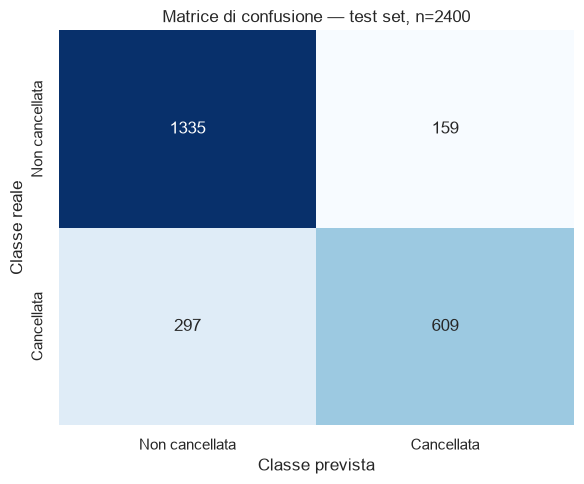

In [51]:
# La matrice di confusione conta previsioni corrette ed errori sul test set.
# y_test contiene gli esiti reali; y_pred contiene le previsioni della regressione
# logistica calcolate prima. labels fissa l’ordine: 0 = non cancellata, 1 = cancellata.
# Le RIGHE sono le classi reali e le COLONNE quelle previste:
# alto-sinistra: non cancellate riconosciute correttamente (veri negativi);
# alto-destra: non cancellate segnalate come cancellate (falsi positivi);
# basso-sinistra: cancellazioni non individuate (falsi negativi);
# basso-destra: cancellazioni individuate correttamente (veri positivi).
matrice = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Creiamo lo spazio del grafico; figsize indica larghezza e altezza in pollici.
plt.figure(figsize=(6, 5))

# Una heatmap colora ogni casella in base al conteggio: un colore più scuro
# indica più prenotazioni. annot=True scrive i valori e fmt="d" li mostra come interi.
# cmap sceglie i colori; cbar=False nasconde la legenda numerica dei colori.
sns.heatmap(
    matrice,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Non cancellata", "Cancellata"],
    yticklabels=["Non cancellata", "Cancellata"],
)

# Le etichette ricordano come leggere righe e colonne. La diagonale contiene
# le classificazioni corrette, le altre due caselle gli errori.
# Il titolo riporta anche il numero di prenotazioni valutate nel test set.
plt.xlabel("Classe prevista")
plt.ylabel("Classe reale")
plt.title(f"Matrice di confusione — test set, n={len(y_test)}")
# Sistemiamo gli spazi per evitare sovrapposizioni e mostriamo il risultato.
plt.tight_layout()
plt.show()

In [52]:
# OBIETTIVO: confrontare due classificatori con lo stesso criterio e scegliere il modello tramite cross-validation.
# Una Random Forest combina molti alberi decisionali: ogni albero applica una serie di domande sulle caratteristiche.
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# clone crea una copia non addestrata con le stesse impostazioni: non riutilizza valori già imparati.
# Così ogni addestramento calcola il preprocessing usando soltanto le proprie righe di training.
# Riutilizziamo lo stesso preprocessing per confrontare solo i classificatori.
modello_rf = Pipeline([
    ("preprocessing", clone(preprocessing)),
    ("classificatore", RandomForestClassifier(
        # Costruiamo 300 alberi, combinando le loro stime per ottenere la previsione della foresta.
        n_estimators=300,
        # Ogni foglia, cioè gruppo finale di un albero, deve contenere almeno due esempi del suo training.
        # Questo limita decisioni basate su singoli casi.
        min_samples_leaf=2,
        # Fissiamo la casualità usata dalla foresta per rendere riproducibile il confronto.
        random_state=42,
        # Usiamo tutti i processori disponibili per elaborare gli alberi in parallelo.
        n_jobs=-1,
    )),
])

# Il dizionario associa un nome leggibile a ciascuna pipeline da confrontare.
# Anche la regressione logistica viene clonata per ripartire senza apprendimento precedente.
candidati = {
    "Regressione logistica": clone(modello),
    "Random Forest": modello_rf,
}

# La cross-validation divide il training set in cinque parti, chiamate fold.
# A turno il modello impara da quattro parti e viene valutato sulla quinta: si ottengono cinque valutazioni.
# Stratified mantiene proporzioni simili delle due classi; shuffle mescola le righe prima di dividerle.
# Il test set rimane fuori da questo confronto: serve dopo la scelta del modello.
# Creiamo le suddivisioni una sola volta: saranno identiche per entrambi.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Memorizziamo gli indici delle righe di ciascun fold, così i due modelli incontrano le stesse suddivisioni.
fold = list(cv.split(X_train, y_train))

# Indichiamo quali punteggi calcolare: accuracy su tutte le classi; precision, recall e F1 sulla classe 1.
# La classe positiva 1 è la cancellazione: vogliamo misurare quanto bene venga individuata.
metriche = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

# La lista inizialmente vuota raccoglierà una riga di risultati per ogni modello.
risultati = []

# Il ciclo ripete la stessa valutazione per ciascuna coppia nome/modello presente nel dizionario.
for nome, candidato in candidati.items():
    # flush=True mostra subito il messaggio, così sappiamo quale valutazione è in corso.
    print(f"Valutazione: {nome}", flush=True)

    # cross_validate addestra copie nuove della pipeline nei diversi fold, poi misura le previsioni
    # sulle righe lasciate fuori da ciascun addestramento. Non usa il test finale.
    punteggi = cross_validate(
        candidato,
        X_train,
        y_train,
        cv=fold,
        scoring=metriche,
        # Eseguiamo le valutazioni dei fold una alla volta; gli alberi della foresta restano parallelizzati.
        n_jobs=1,
        # Se un addestramento fallisce, mostriamo l'errore invece di nasconderlo in un punteggio mancante.
        error_score="raise",
    )

    # Ogni array test_... contiene i cinque punteggi delle parti di validazione: mean ne calcola la media.
    # Qui 'test' nei nomi restituiti dalla funzione indica il fold di validazione, non X_test.
    # La deviazione standard F1 descrive quanto varia il punteggio tra i fold;
    # non è un intervallo di confidenza né l'incertezza di una singola previsione.
    risultati.append({
        "Modello": nome,
        "Accuracy CV": punteggi["test_accuracy"].mean(),
        "Precision CV": punteggi["test_precision"].mean(),
        "Recall CV": punteggi["test_recall"].mean(),
        "F1 CV": punteggi["test_f1"].mean(),
        "Deviazione standard F1": punteggi["test_f1"].std(),
    })

# Convertiamo i risultati in una tabella, usiamo i nomi dei modelli come indice e ordiniamo per F1.
# ascending=False mette in cima il valore maggiore. Qui scegliamo F1 come criterio di confronto.
confronto = (
    pd.DataFrame(risultati)
    .set_index("Modello")
    .sort_values("F1 CV", ascending=False)
)

# Arrotondiamo soltanto la visualizzazione a tre decimali: la tabella conserva i valori originali.
display(confronto.round(3))

# Il primo nome della tabella ordinata è il candidato con F1 medio maggiore.
# Cloniamo quel candidato per addestrare un modello finale nuovo su tutto il training disponibile.
# La scelta avviene sulla cross-validation, senza usare il test.
nome_scelto = confronto.index[0]
modello_finale = clone(candidati[nome_scelto])

# Ora usiamo l'intero training set, non quattro fold, per imparare il modello scelto.
# Le previsioni sul test danno una valutazione finale distinta da quella usata per scegliere.
# Addestramento su tutto il training set.
modello_finale.fit(X_train, y_train)
y_pred_finale = modello_finale.predict(X_test)

print(f"\nModello scelto tramite F1 CV: {nome_scelto}")
print("\nRisultati sul test set:")

# Precision, recall e F1 qui vengono calcolate sul test finale, separatamente per ciascuna classe.
# y_pred_finale si riferisce al modello scelto; y_pred, creato prima, rimane quello della regressione logistica.
print(classification_report(
    y_test,
    y_pred_finale,
    labels=[0, 1],
    target_names=["Non cancellata", "Cancellata"],
    zero_division=0,
))

print("Matrice di confusione:")
print(confusion_matrix(y_test, y_pred_finale, labels=[0, 1]))

Valutazione: Regressione logistica
Valutazione: Random Forest


,Accuracy CV,Precision CV,Recall CV,F1 CV,Deviazione standard F1
Modello,,,,,
Random Forest,0.842,0.857,0.697,0.769,0.017
Regressione logistica,0.805,0.774,0.681,0.724,0.018



Modello scelto tramite F1 CV: Random Forest

Risultati sul test set:
                precision    recall  f1-score   support

Non cancellata       0.83      0.94      0.88      1494
    Cancellata       0.88      0.68      0.76       906

      accuracy                           0.84      2400
     macro avg       0.85      0.81      0.82      2400
  weighted avg       0.85      0.84      0.84      2400

Matrice di confusione:
[[1408   86]
 [ 293  613]]


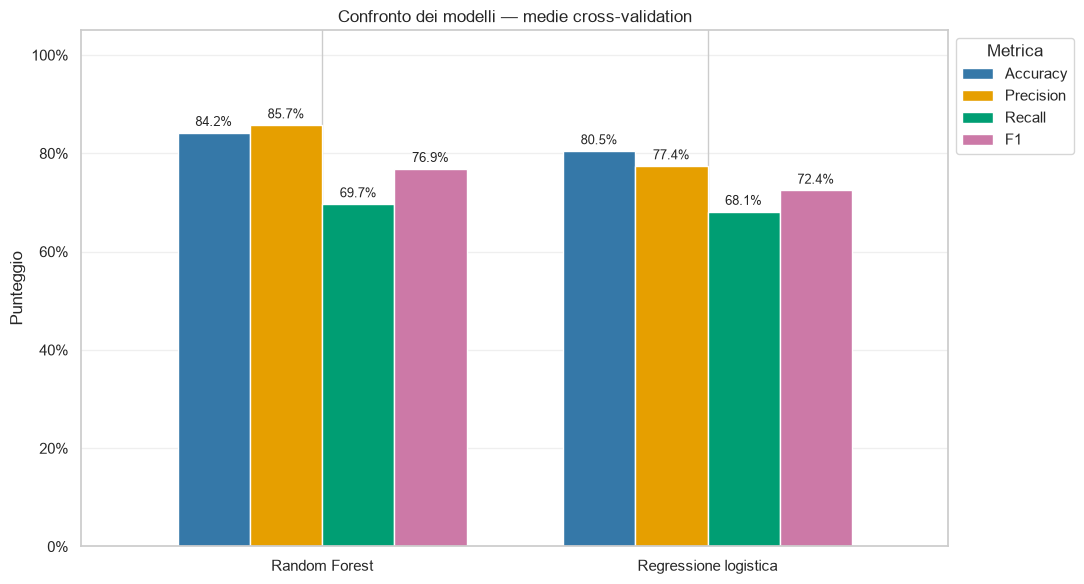

In [53]:
# Confrontiamo i modelli con quattro metriche medie della cross-validation.
# La tabella confronto è stata creata nella cella precedente: ogni riga è un modello.
# Le metriche descrivono le prestazioni sui fold di validazione, prima della media.
import matplotlib.pyplot as plt
# PercentFormatter permette di mostrare valori fra 0 e 1 come percentuali.
from matplotlib.ticker import PercentFormatter

# Selezioniamo solo le colonne da disegnare e abbreviamo i nomi con rename.
# Accuracy: fra tutte le prenotazioni, quota classificata correttamente.
# Precision: fra quelle previste cancellate, quota che è davvero cancellata.
# Recall: fra quelle davvero cancellate, quota che il modello riesce a individuare.
# F1: media armonica di precision e recall; è alta quando entrambe sono alte.
# Qui precision, recall e F1 si riferiscono alla classe positiva 1 (cancellata).
metriche = confronto[
    ["Accuracy CV", "Precision CV", "Recall CV", "F1 CV"]
].rename(columns={
    "Accuracy CV": "Accuracy",
    "Precision CV": "Precision",
    "Recall CV": "Recall",
    "F1 CV": "F1",
})

# Ogni modello ha un gruppo di quattro barre, una per metrica.
# kind sceglie le barre verticali; rot=0 mantiene orizzontali i nomi dei modelli.
# I quattro colori permettono di riconoscere la stessa metrica nei diversi gruppi.
ax = metriche.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0,
    width=0.75,
    color=["#3578A8", "#E69F00", "#009E73", "#CC79A7"],
)

# Mostra il valore sopra ogni barra.
# containers raccoglie i gruppi di barre. Li percorriamo per aggiungere le etichette.
# La scrittura :.1% trasforma, ad esempio, 0.825 in 82.5% (con un solo decimale).
for gruppo in ax.containers:
    ax.bar_label(
        gruppo,
        labels=[f"{valore:.1%}" for valore in gruppo.datavalues],
        padding=3,
        fontsize=9,
    )

# Aggiungiamo titolo e nomi degli assi. Per queste quattro metriche valori più
# alti indicano risultati migliori, ma precision e recall descrivono errori diversi.
ax.set_title("Confronto dei modelli — medie cross-validation")
ax.set_xlabel("")
ax.set_ylabel("Punteggio")
# Lasciamo un piccolo margine sopra 1 per le etichette. xmax=1 indica che
# il valore 1 corrisponde al 100%; i punteggi restano numeri fra 0 e 1.
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
# Spostiamo la legenda fuori dal grafico. La griglia orizzontale aiuta la lettura
# e set_axisbelow la mette dietro alle barre.
ax.legend(title="Metrica", loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Queste barre mostrano medie: non rappresentano la variabilità tra i fold.
# Adattiamo gli spazi della figura e visualizziamo il grafico.
plt.tight_layout()
plt.show()

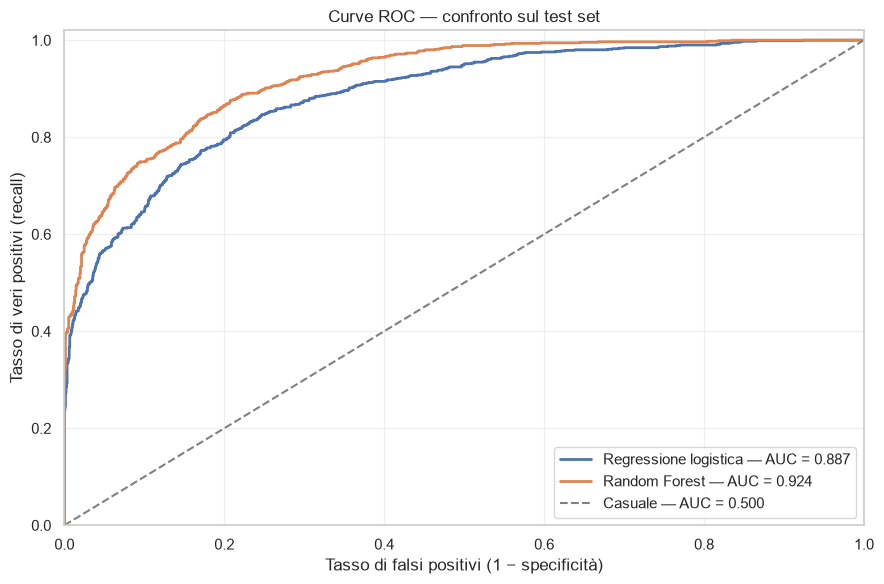

,AUC test
Modello,
Random Forest,0.9236
Regressione logistica,0.8870


In [54]:
# La curva ROC confronta i modelli considerando diverse soglie di decisione.
# L’AUC è l’area sotto la curva: sintetizza quanto il modello riesce a ordinare
# le cancellazioni con probabilità più alte rispetto alle prenotazioni non cancellate.
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score

# Un dizionario associa un nome leggibile a ogni modello da confrontare.
# clone copia configurazione e preprocessing, ma non l’addestramento già eseguito:
# alleneremo copie nuove senza modificare i modelli delle celle precedenti.
modelli_roc = {
    "Regressione logistica": clone(modello),
    "Random Forest": clone(modello_rf),
}

# La lista raccoglierà una riga di risultati per modello.
# subplots restituisce la figura complessiva e il riquadro su cui disegnare (ax).
risultati_auc = []
fig, ax = plt.subplots(figsize=(9, 6))

# Il ciclo ripete gli stessi passaggi per i due modelli, usando lo stesso
# training set per imparare e lo stesso test set per confrontare i risultati.
for nome, classificatore in modelli_roc.items():
    # fit impara la relazione tra le caratteristiche X_train e gli esiti y_train.
    # Le trasformazioni della pipeline vengono apprese sul training e poi riutilizzate.
    classificatore.fit(X_train, y_train)

    # Probabilità della classe 1: prenotazione cancellata.
    # predict_proba restituisce una colonna per ogni classe. [:, 1] seleziona
    # tutte le righe e la seconda colonna, cioè la probabilità della classe 1.
    # Usiamo probabilità, non le sole etichette 0/1, per poter variare la soglia.
    probabilita = classificatore.predict_proba(X_test)[:, 1]

    # Una soglia decide da quale probabilità segnalare una cancellazione.
    # roc_curve prova soglie diverse e calcola i relativi TASSI (non conteggi):
    # falsi positivi = non cancellate segnalate / tutte le non cancellate;
    # veri positivi = cancellazioni individuate / tutte le cancellazioni (recall).
    falsi_positivi, veri_positivi, soglie = roc_curve(
        y_test, probabilita
    )
    # AUC = 0,5 indica un ordinamento casuale; AUC = 1 indica un ordinamento perfetto.
    # L’AUC non è la percentuale di previsioni corrette a una singola soglia.
    auc = roc_auc_score(y_test, probabilita)

    # Tracciamo una linea per modello; nella legenda mostriamo anche l’AUC.
    # :.3f limita il valore visualizzato a tre cifre decimali.
    ax.plot(
        falsi_positivi,
        veri_positivi,
        linewidth=2,
        label=f"{nome} — AUC = {auc:.3f}",
    )

    # Conserviamo nome e AUC in un dizionario, aggiunto alla lista dei risultati.
    risultati_auc.append({
        "Modello": nome,
        "AUC test": auc,
    })

# Riferimento di un classificatore casuale.
# La diagonale unisce (0, 0) e (1, 1): è il riferimento di un ordinamento casuale.
# Una buona curva tende verso l’angolo in alto a sinistra: molto recall e pochi falsi positivi.
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Casuale — AUC = 0.500",
)

# L’asse orizzontale misura i falsi allarmi; quello verticale le cancellazioni trovate.
# La specificità è la quota di non cancellate riconosciute: 1 − specificità è il tasso
# di falsi positivi. Entrambi gli assi usano proporzioni fra 0 e 1.
ax.set_title("Curve ROC — confronto sul test set")
ax.set_xlabel("Tasso di falsi positivi (1 − specificità)")
ax.set_ylabel("Tasso di veri positivi (recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

# Sistemiamo gli spazi e visualizziamo le due curve nello stesso grafico.
plt.tight_layout()
plt.show()

# Trasformiamo la lista di risultati in una tabella: set_index usa i nomi
# come etichette delle righe; sort_values mette prima il modello con AUC maggiore.
confronto_auc = (
    pd.DataFrame(risultati_auc)
    .set_index("Modello")
    .sort_values("AUC test", ascending=False)
)

# Mostriamo la tabella con quattro decimali. Il test serve alla valutazione finale:
# scegliere soglie o modificare modelli in base a questi risultati richiederebbe nuova validazione.
display(confronto_auc.round(4))

In [57]:
# CONTROLLO DI OVERFITTING: il modello rende molto meglio sui dati da cui ha imparato?
# Confrontiamo training e validazione negli stessi cinque fold già usati nel notebook.
# In ogni turno si impara da 7.680 righe e si valuta su altre 1.920 righe del training originale.
# Il test finale X_test/y_test non viene usato per questo controllo.
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

# Copiamo le impostazioni delle pipeline senza modificarle né conservarne l'addestramento.
# La logistica offre un riferimento: una maggiore complessità può produrre un divario maggiore.
modelli_overfitting = {
    'Regressione logistica': clone(modello),
    'Random Forest': clone(modello_rf),
}
metriche_overfitting = {
    'f1': 'f1',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
}
righe_overfitting = []
fold_overfitting = []
punteggi_overfitting = {}

for nome_overfitting, candidato_overfitting in modelli_overfitting.items():
    print('Controllo training/validazione:', nome_overfitting, flush=True)

    # return_train_score=True aggiunge i punteggi sulle righe usate per addestrare.
    # Senza questa opzione cross_validate restituisce normalmente solo quelli di validazione.
    # La pipeline impara imputazione, scala e categorie dal training di ogni singolo fold.
    score_overfitting = cross_validate(
        candidato_overfitting,
        X_train,
        y_train,
        cv=fold,
        scoring=metriche_overfitting,
        return_train_score=True,
        n_jobs=1,
        error_score='raise',
    )
    punteggi_overfitting[nome_overfitting] = score_overfitting

    # train_f1 e test_f1 sono array di cinque valori, uno per fold.
    # Qui test_f1 indica la VALIDAZIONE del fold, non il test finale X_test.
    # Sottraiamo valori dello stesso fold per confrontare lo stesso addestramento.
    gap_f1_overfitting = score_overfitting['train_f1'] - score_overfitting['test_f1']
    righe_overfitting.append({
        'Modello': nome_overfitting,
        'F1 training': score_overfitting['train_f1'].mean(),
        'F1 validazione': score_overfitting['test_f1'].mean(),
        'Gap F1 (punti)': gap_f1_overfitting.mean() * 100,
        'Accuracy training': score_overfitting['train_accuracy'].mean(),
        'Accuracy validazione': score_overfitting['test_accuracy'].mean(),
        'Precision training': score_overfitting['train_precision'].mean(),
        'Precision validazione': score_overfitting['test_precision'].mean(),
        'Recall training': score_overfitting['train_recall'].mean(),
        'Recall validazione': score_overfitting['test_recall'].mean(),
        'Std F1 validazione': score_overfitting['test_f1'].std(),
    })

    # Conserviamo anche i cinque confronti separati per verificare la coerenza del divario.
    # range(1, 6) produce 1, 2, 3, 4, 5: numeri leggibili per identificare i fold.
    fold_overfitting.append(pd.DataFrame({
        'Modello': nome_overfitting,
        'Fold': range(1, len(fold) + 1),
        'F1 training': score_overfitting['train_f1'],
        'F1 validazione': score_overfitting['test_f1'],
        'Gap F1 (punti)': gap_f1_overfitting * 100,
    }))

confronto_overfitting = pd.DataFrame(righe_overfitting).set_index('Modello')
dettaglio_overfitting = pd.concat(fold_overfitting, ignore_index=True)

# Un gap positivo significa che il punteggio è più alto sui dati di addestramento.
# Per esempio 0,90 - 0,75 = 0,15, cioè 15 punti sulla scala percentuale dell'F1.
# La deviazione standard descrive la variabilità tra fold: non è un intervallo di confidenza.
# Il divario è un indizio di sovradattamento; non prova che la causa sia soltanto max_depth.
print('Medie sui cinque fold:')
display(confronto_overfitting.round(4))
print('Dettaglio per fold:')
display(dettaglio_overfitting.round(4))
print('Nessuna modifica alle impostazioni dei modelli e nessun nuovo utilizzo del test finale.')

Controllo training/validazione: Regressione logistica
Controllo training/validazione: Random Forest
Medie sui cinque fold:


,F1 training,F1 validazione,Gap F1 (punti),Accuracy training,Accuracy validazione,Precision training,Precision validazione,Recall training,Recall validazione,Std F1 validazione
Modello,,,,,,,,,,
Regressione logistica,0.7370,0.7244,1.2558,0.8134,0.8046,0.7874,0.7739,0.6926,0.6812,0.0178
Random Forest,0.8786,0.7685,11.0117,0.9144,0.8418,0.9450,0.8573,0.8209,0.6967,0.0165


Dettaglio per fold:


,Modello,Fold,F1 training,F1 validazione,Gap F1 (punti)
0,Regressione logistica,1,0.7340,0.7300,0.3979
1,Regressione logistica,2,0.7334,0.7426,-0.9252
2,Regressione logistica,3,0.7373,0.7381,-0.0737
3,Regressione logistica,4,0.7424,0.6927,4.9732
4,Regressione logistica,5,0.7377,0.7187,1.9070
5,Random Forest,1,0.8778,0.7723,10.5564
6,Random Forest,2,0.8780,0.7824,9.5638
7,Random Forest,3,0.8775,0.7859,9.1668
8,Random Forest,4,0.8812,0.7400,14.1203
9,Random Forest,5,0.8784,0.7619,11.6514


Nessuna modifica alle impostazioni dei modelli e nessun nuovo utilizzo del test finale.


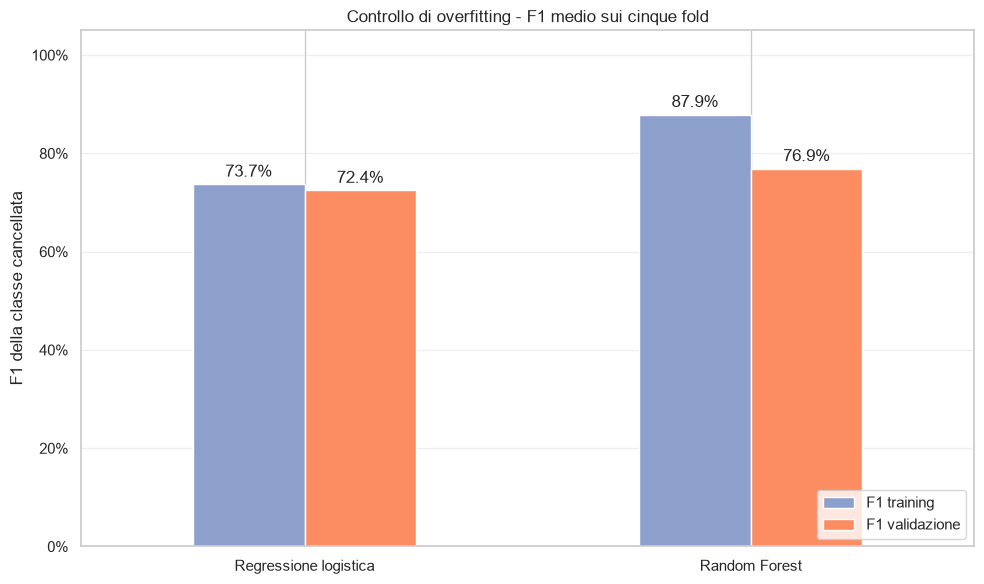

In [58]:
# GRAFICO DEL DIVARIO: due barre per modello, calcolate dagli stessi cinque fold.
# Le barre mostrano medie, non la variabilità delle singole suddivisioni.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ax_overfitting = confronto_overfitting[['F1 training', 'F1 validazione']].plot(
    kind='bar',
    figsize=(10, 6),
    rot=0,
    color=['#8DA0CB', '#FC8D62'],
)
for barre_overfitting in ax_overfitting.containers:
    ax_overfitting.bar_label(
        barre_overfitting,
        labels=[f'{valore:.1%}' for valore in barre_overfitting.datavalues],
        padding=3,
    )

ax_overfitting.set_title('Controllo di overfitting - F1 medio sui cinque fold')
ax_overfitting.set_xlabel('')
ax_overfitting.set_ylabel('F1 della classe cancellata')
ax_overfitting.set_ylim(0, 1.05)
ax_overfitting.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_overfitting.grid(axis='y', alpha=0.3)
ax_overfitting.set_axisbelow(True)
ax_overfitting.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Interpretazione del controllo di overfitting

Il confronto usa gli stessi cinque fold stratificati del notebook, con F1 riferito alla classe cancellata. Ogni modello viene misurato sia sulle 7.680 righe usate per imparare in quel turno sia sulle 1.920 righe lasciate fuori. Il test finale non viene riutilizzato.

| Modello | F1 medio training | F1 medio validazione | Differenza |
|---|---:|---:|---:|
| Regressione logistica | 0,7370 | 0,7244 | 1,26 punti |
| Random Forest | 0,8786 | 0,7685 | 11,01 punti |

La Random Forest mostra un segnale consistente di sovradattamento: il divario è positivo in tutti i cinque fold e varia da circa 9,17 a 14,12 punti. Le sue previsioni funzionano meglio sui dati da cui ha imparato che su quelli lasciati fuori dall'addestramento.

La foresta conserva comunque un F1 di validazione maggiore della logistica. Il controllo non dimostra che il divario sia causato soltanto da `max_depth=None`, né che limitarne la profondità migliori necessariamente la validazione. Per verificarlo occorrerebbe confrontare impostazioni alternative sugli stessi fold, scegliendo in base ai punteggi di validazione e osservando anche il divario.

Le impostazioni iniziali restano invariate: 300 alberi, `max_depth=None`, `min_samples_leaf=2`. Questo controllo descrive la cross-validation casuale dell'esercizio; la presenza di profili coincidenti e la generalizzazione nel tempo richiedono valutazioni dedicate, come discusso in confronto_colonne_hotel.ipynb.

In [59]:
# RICERCA DI UNA FORESTA CON F1 DI VALIDAZIONE PIU ALTO E DIVARIO PIU PICCOLO.
# Manteniamo fissi dati, colonne, preprocessing, cinque fold, 300 alberi e random_state.
# Cambiamo soltanto due parametri della complessità degli alberi.
# Il test finale non entra nella ricerca.
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Le doppie sottolineature indicano un parametro del passaggio 'classificatore' della pipeline.
# max_depth limita il numero di livelli; None non impone un limite esplicito.
# min_samples_leaf richiede un numero minimo di esempi in ciascuna foglia.
# La combinazione None/2 è la baseline, inclusa per rifare lo stesso confronto nella ricerca.
griglia_rf = {
    'classificatore__max_depth': [None, 10, 20, 30, 40, 50, 60],
    'classificatore__min_samples_leaf': [1, 2, 3, 5, 10],
}
metriche_tuning_rf = {
    'f1': 'f1', 'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
}

# GridSearchCV prova tutte le coppie: 7 profondità per 5 dimensioni minime = 35 configurazioni.
# Ogni configurazione richiede cinque addestramenti, uno per fold: in totale 175.
# return_train_score permette di misurare anche il divario training-validazione.
# refit=False rimanda il fit finale: prima scegliamo un candidato che rispetti entrambi gli obiettivi.
# Un solo fold alla volta evita di sommare più parallelizzazioni: la foresta parallelizza già gli alberi.
ricerca_rf = GridSearchCV(
    estimator=clone(modello_rf),
    param_grid=griglia_rf,
    scoring=metriche_tuning_rf,
    cv=fold,
    return_train_score=True,
    refit=False,
    n_jobs=1,
    error_score='raise',
    verbose=2,
)
ricerca_rf.fit(X_train, y_train)

# cv_results_ conserva parametri, medie e valori separati per ciascun fold.
# Manteniamo l'indice originale per ritrovare i parametri e i cinque punteggi del candidato scelto.
cv_tuning_rf = pd.DataFrame(ricerca_rf.cv_results_)
tabella_tuning_rf = pd.DataFrame({
    'max_depth': cv_tuning_rf['params'].map(
        lambda p: 'None' if p['classificatore__max_depth'] is None
        else str(p['classificatore__max_depth'])),
    'min_samples_leaf': cv_tuning_rf['params'].map(
        lambda p: p['classificatore__min_samples_leaf']),
    'F1 training': cv_tuning_rf['mean_train_f1'],
    'F1 validazione': cv_tuning_rf['mean_test_f1'],
    'Gap F1 (punti)': (cv_tuning_rf['mean_train_f1'] - cv_tuning_rf['mean_test_f1']) * 100,
    'Std F1 validazione': cv_tuning_rf['std_test_f1'],
    'Accuracy validazione': cv_tuning_rf['mean_test_accuracy'],
    'Precision validazione': cv_tuning_rf['mean_test_precision'],
    'Recall validazione': cv_tuning_rf['mean_test_recall'],
})
indice_baseline_rf = tabella_tuning_rf.index[
    (tabella_tuning_rf['max_depth'] == 'None') &
    (tabella_tuning_rf['min_samples_leaf'] == 2)
][0]
baseline_tuning_rf = tabella_tuning_rf.loc[indice_baseline_rf]

# Prima regola: il candidato deve migliorare F1 e ridurre il divario rispetto alla baseline.
# Fra quelli ammessi scegliamo F1 maggiore; a parità di F1 preferiamo il gap minore.
# La piccola tolleranza evita di considerare differenze di arrotondamento come miglioramenti.
tolleranza_rf = 1e-12
ammessi_tuning_rf = tabella_tuning_rf.loc[
    (tabella_tuning_rf['F1 validazione'] > baseline_tuning_rf['F1 validazione'] + tolleranza_rf) &
    (tabella_tuning_rf['Gap F1 (punti)'] < baseline_tuning_rf['Gap F1 (punti)'] - tolleranza_rf)
].sort_values(['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True])
indice_massimo_f1_rf = tabella_tuning_rf.sort_values(
    ['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True]
).index[0]

print('Baseline inclusa nella ricerca:')
display(tabella_tuning_rf.loc[[indice_baseline_rf]].round(4))
print('Dieci configurazioni con F1 di validazione più alto:')
display(tabella_tuning_rf.sort_values('F1 validazione', ascending=False).head(10).round(4))
print('Configurazioni che migliorano entrambi gli obiettivi:', len(ammessi_tuning_rf))

if not ammessi_tuning_rf.empty:
    indice_scelto_rf = ammessi_tuning_rf.index[0]
    print('Candidato scelto per F1 più alto e minore divario:')
    display(tabella_tuning_rf.loc[[indice_scelto_rf]].round(4))
else:
    # Conserviamo la baseline se nessuna configurazione raggiunge entrambi gli obiettivi.
    indice_scelto_rf = indice_baseline_rf
    print('Nessun miglioramento congiunto nella griglia: la baseline resta il riferimento.')
    print('Il massimo F1 assoluto è mostrato separatamente, senza dichiararlo migliore su entrambi gli obiettivi.')

# Il massimo F1 assoluto potrebbe avere un gap più grande: non lo confondiamo con la scelta congiunta.
print('Configurazione con F1 massimo in assoluto:')
display(tabella_tuning_rf.loc[[indice_massimo_f1_rf]].round(4))
print('Nessun utilizzo del test finale e nessuna modifica della foresta originale.')

Fitting 5 folds for each of 35 candidates, totalling 175 fits
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=1; total time=   1.0s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=1; total time=   1.0s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=1; total time=   1.0s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=1; total time=   0.9s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=1; total time=   0.9s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=2; total time=   0.7s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=2; total time=   0.7s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=2; total time=   0.7s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=2; total time=   0.7s
[CV] END classificatore__max_depth=None, classificatore__min_samples_leaf=

,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
1,None,2,0.8786,0.7685,11.0117,0.0165,0.8418,0.8573,0.6967


Dieci configurazioni con F1 di validazione più alto:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
20,40,1,0.9983,0.7812,21.7127,0.0178,0.8469,0.8473,0.7248
10,20,1,0.9423,0.7810,16.1353,0.0160,0.8485,0.8591,0.7160
30,60,1,0.9983,0.7806,21.7691,0.0153,0.8468,0.8486,0.7229
25,50,1,0.9983,0.7802,21.8076,0.0165,0.8465,0.8478,0.7229
15,30,1,0.9963,0.7802,21.6160,0.0185,0.8466,0.8485,0.7223
0,None,1,0.9983,0.7801,21.8226,0.0157,0.8464,0.8478,0.7226
16,30,2,0.8753,0.7701,10.5208,0.0174,0.8428,0.8586,0.6983
26,50,2,0.8786,0.7686,11.0082,0.0169,0.8418,0.8570,0.6969
21,40,2,0.8784,0.7686,10.9854,0.0176,0.8416,0.8557,0.6978
31,60,2,0.8786,0.7685,11.0117,0.0165,0.8418,0.8573,0.6967


Configurazioni che migliorano entrambi gli obiettivi: 3
Candidato scelto per F1 più alto e minore divario:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
16,30,2,0.8753,0.7701,10.5208,0.0174,0.8428,0.8586,0.6983


Configurazione con F1 massimo in assoluto:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
20,40,1,0.9983,0.7812,21.7127,0.0178,0.8469,0.8473,0.7248


Nessun utilizzo del test finale e nessuna modifica della foresta originale.


In [60]:
# RAFFINAMENTO LOCALE: la prima griglia ha indicato max_depth=30 e min_samples_leaf=2
# come migliore coppia che aumenta F1 di validazione e riduce il gap della baseline.
# Proviamo profondità intermedie non ancora esaminate, mantenendo min_samples_leaf=2.
# Anche questa scelta usa soltanto la cross-validation: i nuovi punteggi restano risultati di selezione.
# La griglia iniziale viene conservata per distinguere le due fasi della ricerca.
cv_tuning_rf_iniziale = pd.DataFrame(ricerca_rf.cv_results_).copy()
tabella_tuning_rf_iniziale = tabella_tuning_rf.iloc[:len(cv_tuning_rf_iniziale)].copy()

griglia_locale_rf = {
    'classificatore__max_depth': [22, 24, 26, 28, 32, 34],
    'classificatore__min_samples_leaf': [2],
}
ricerca_locale_rf = GridSearchCV(
    estimator=clone(modello_rf),
    param_grid=griglia_locale_rf,
    scoring=metriche_tuning_rf,
    cv=fold,
    return_train_score=True,
    refit=False,
    n_jobs=1,
    error_score='raise',
    verbose=1,
)
ricerca_locale_rf.fit(X_train, y_train)

# Uniamo i risultati dei due passaggi. Nessuna configurazione locale era nella prima griglia.
cv_tuning_rf = pd.concat(
    [cv_tuning_rf_iniziale, pd.DataFrame(ricerca_locale_rf.cv_results_)],
    ignore_index=True,
)
tabella_tuning_rf = pd.DataFrame({
    'max_depth': cv_tuning_rf['params'].map(
        lambda p: 'None' if p['classificatore__max_depth'] is None
        else str(p['classificatore__max_depth'])),
    'min_samples_leaf': cv_tuning_rf['params'].map(
        lambda p: p['classificatore__min_samples_leaf']),
    'F1 training': cv_tuning_rf['mean_train_f1'],
    'F1 validazione': cv_tuning_rf['mean_test_f1'],
    'Gap F1 (punti)': (cv_tuning_rf['mean_train_f1'] - cv_tuning_rf['mean_test_f1']) * 100,
    'Std F1 validazione': cv_tuning_rf['std_test_f1'],
    'Accuracy validazione': cv_tuning_rf['mean_test_accuracy'],
    'Precision validazione': cv_tuning_rf['mean_test_precision'],
    'Recall validazione': cv_tuning_rf['mean_test_recall'],
})

# Applichiamo la stessa regola fissata prima della ricerca: migliorare entrambi gli obiettivi.
ammessi_tuning_rf = tabella_tuning_rf.loc[
    (tabella_tuning_rf['F1 validazione'] > baseline_tuning_rf['F1 validazione'] + tolleranza_rf) &
    (tabella_tuning_rf['Gap F1 (punti)'] < baseline_tuning_rf['Gap F1 (punti)'] - tolleranza_rf)
].sort_values(['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True])
indice_scelto_rf = ammessi_tuning_rf.index[0] if not ammessi_tuning_rf.empty else indice_baseline_rf
indice_massimo_f1_rf = tabella_tuning_rf.sort_values(
    ['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True]
).index[0]

print('Configurazioni complessive valutate:', len(tabella_tuning_rf))
print('Risultati del raffinamento locale:')
display(tabella_tuning_rf.iloc[len(tabella_tuning_rf_iniziale):].round(4))
print('Migliori configurazioni che rispettano entrambi gli obiettivi:')
display(ammessi_tuning_rf.head(10).round(4))
print('Confronto baseline/candidato scelto/massimo F1 assoluto:')
display(tabella_tuning_rf.loc[
    [indice_baseline_rf, indice_scelto_rf, indice_massimo_f1_rf]
].round(4))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Configurazioni complessive valutate: 41
Risultati del raffinamento locale:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
35,22,2,0.8613,0.7677,9.3589,0.0186,0.8417,0.8591,0.6942
36,24,2,0.8680,0.7700,9.7956,0.0191,0.8430,0.8602,0.6972
37,26,2,0.8704,0.7691,10.1304,0.0165,0.8424,0.8595,0.6961
38,28,2,0.8735,0.7706,10.2909,0.0167,0.8429,0.8578,0.6997
39,32,2,0.8763,0.7701,10.6273,0.0172,0.8426,0.8573,0.6992
40,34,2,0.8769,0.7710,10.5956,0.0199,0.8433,0.8588,0.6997


Migliori configurazioni che rispettano entrambi gli obiettivi:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
40,34,2,0.8769,0.7710,10.5956,0.0199,0.8433,0.8588,0.6997
38,28,2,0.8735,0.7706,10.2909,0.0167,0.8429,0.8578,0.6997
16,30,2,0.8753,0.7701,10.5208,0.0174,0.8428,0.8586,0.6983
39,32,2,0.8763,0.7701,10.6273,0.0172,0.8426,0.8573,0.6992
36,24,2,0.8680,0.7700,9.7956,0.0191,0.8430,0.8602,0.6972
37,26,2,0.8704,0.7691,10.1304,0.0165,0.8424,0.8595,0.6961
26,50,2,0.8786,0.7686,11.0082,0.0169,0.8418,0.8570,0.6969
21,40,2,0.8784,0.7686,10.9854,0.0176,0.8416,0.8557,0.6978


Confronto baseline/candidato scelto/massimo F1 assoluto:


,max_depth,min_samples_leaf,F1 training,F1 validazione,Gap F1 (punti),Std F1 validazione,Accuracy validazione,Precision validazione,Recall validazione
1,None,2,0.8786,0.7685,11.0117,0.0165,0.8418,0.8573,0.6967
40,34,2,0.8769,0.7710,10.5956,0.0199,0.8433,0.8588,0.6997
20,40,1,0.9983,0.7812,21.7127,0.0178,0.8469,0.8473,0.7248


In [61]:
# SCELTA FISSATA E CONTROLLO DI STABILITA, SENZA ALTRO TUNING.
# La scelta proviene dalla ricerca sui cinque fold originali: non usiamo il test finale.
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate

parametri_rf_ottimizzati = dict(cv_tuning_rf.loc[indice_scelto_rf, 'params'])
parametri_baseline_rf = dict(cv_tuning_rf.loc[indice_baseline_rf, 'params'])
print('Parametri del candidato scelto:', parametri_rf_ottimizzati)

# Confronto appaiato sui cinque fold originali: ogni sottrazione riguarda lo stesso turno.
f1_baseline_fold_rf = np.array([
    cv_tuning_rf.loc[indice_baseline_rf, f'split{k}_test_f1'] for k in range(len(fold))
], dtype=float)
f1_scelto_fold_rf = np.array([
    cv_tuning_rf.loc[indice_scelto_rf, f'split{k}_test_f1'] for k in range(len(fold))
], dtype=float)
confronto_fold_tuning_rf = pd.DataFrame({
    'Fold': range(1, len(fold) + 1),
    'F1 baseline': f1_baseline_fold_rf,
    'F1 candidato': f1_scelto_fold_rf,
    'Delta F1 (punti)': (f1_scelto_fold_rf - f1_baseline_fold_rf) * 100,
})
print('Differenze sui fold originali:')
display(confronto_fold_tuning_rf.round(4))

# Il guadagno è piccolo: controlliamo la stessa coppia di configurazioni con altri due seed.
# I seed 17 e 123 cambiano soltanto la distribuzione delle righe nei cinque fold.
# Dati, colonne e impostazioni dei classificatori restano gli stessi.
# Questo riusa i dati di training: è un controllo di stabilità, non un test indipendente.
righe_stabilita_rf = []
for nome_stabilita_rf, indice_stabilita_rf in [
    ('Baseline', indice_baseline_rf), ('Candidato scelto', indice_scelto_rf)
]:
    righe_stabilita_rf.append({
        'Seed fold': 42,
        'Modello': nome_stabilita_rf,
        'F1 training': cv_tuning_rf.loc[indice_stabilita_rf, 'mean_train_f1'],
        'F1 validazione': cv_tuning_rf.loc[indice_stabilita_rf, 'mean_test_f1'],
        'Gap F1 (punti)': (
            cv_tuning_rf.loc[indice_stabilita_rf, 'mean_train_f1'] -
            cv_tuning_rf.loc[indice_stabilita_rf, 'mean_test_f1']) * 100,
    })

punteggi_stabilita_rf = {}
for seme_fold_rf in [17, 123]:
    fold_stabilita_rf = list(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=seme_fold_rf
    ).split(X_train, y_train))
    for nome_stabilita_rf, parametri_stabilita_rf in [
        ('Baseline', parametri_baseline_rf), ('Candidato scelto', parametri_rf_ottimizzati)
    ]:
        print('Controllo stabilità:', seme_fold_rf, nome_stabilita_rf, flush=True)
        pipeline_stabilita_rf = clone(modello_rf).set_params(**parametri_stabilita_rf)
        score_stabilita_rf = cross_validate(
            pipeline_stabilita_rf, X_train, y_train, cv=fold_stabilita_rf,
            scoring='f1', return_train_score=True, n_jobs=1, error_score='raise',
        )
        punteggi_stabilita_rf[(seme_fold_rf, nome_stabilita_rf)] = score_stabilita_rf
        righe_stabilita_rf.append({
            'Seed fold': seme_fold_rf,
            'Modello': nome_stabilita_rf,
            'F1 training': score_stabilita_rf['train_score'].mean(),
            'F1 validazione': score_stabilita_rf['test_score'].mean(),
            'Gap F1 (punti)': (
                score_stabilita_rf['train_score'] - score_stabilita_rf['test_score']).mean() * 100,
        })
tabella_stabilita_rf = pd.DataFrame(righe_stabilita_rf)
print('Controllo con tre diverse suddivisioni del training:')
display(tabella_stabilita_rf.round(4))

# Prepariamo una pipeline addestrata e riutilizzabile, conservando la foresta originale.
# Fit su tutto X_train non aggiunge una nuova prova della qualità: prepara soltanto il modello all'uso.
# Non calcoliamo previsioni o metriche sul test durante la ricerca.
modello_rf_candidato_34 = clone(modello_rf).set_params(**parametri_rf_ottimizzati)
modello_rf_candidato_34.fit(X_train, y_train)
print('modello_rf_candidato_34 è pronto. Il modello_rf originale resta invariato.')

Parametri del candidato scelto: {'classificatore__max_depth': 34, 'classificatore__min_samples_leaf': 2}
Differenze sui fold originali:


,Fold,F1 baseline,F1 candidato,Delta F1 (punti)
0,1,0.7723,0.7760,0.3729
1,2,0.7824,0.7885,0.6109
2,3,0.7859,0.7913,0.5416
3,4,0.7400,0.7369,-0.3123
4,5,0.7619,0.7621,0.0216


Controllo stabilità: 17 Baseline
Controllo stabilità: 17 Candidato scelto
Controllo stabilità: 123 Baseline
Controllo stabilità: 123 Candidato scelto
Controllo con tre diverse suddivisioni del training:


,Seed fold,Modello,F1 training,F1 validazione,Gap F1 (punti)
0,42,Baseline,0.8786,0.7685,11.0117
1,42,Candidato scelto,0.8769,0.7710,10.5956
2,17,Baseline,0.8771,0.7678,10.9286
3,17,Candidato scelto,0.8764,0.7659,11.0458
4,123,Baseline,0.8788,0.7707,10.8037
5,123,Candidato scelto,0.8777,0.7680,10.9761


modello_rf_ottimizzato è pronto. Il modello_rf originale resta invariato.


In [62]:
# CONTROLLO DI UN SECONDO COMPROMESSO: max_depth=24, min_samples_leaf=2.
# Il candidato 34/2 non mantiene il vantaggio con gli altri seed dei fold.
# 24/2 aveva F1 simile nella ricerca iniziale e un divario più basso: lo confrontiamo
# nelle stesse tre suddivisioni. E un confronto aggiuntivo sui dati di training,
# non una verifica indipendente su nuovi dati e non una garanzia di miglioramento.
indice_prudente_rf = tabella_tuning_rf.index[
    (tabella_tuning_rf['max_depth'] == '24') &
    (tabella_tuning_rf['min_samples_leaf'] == 2)
][0]
parametri_prudenti_rf = dict(cv_tuning_rf.loc[indice_prudente_rf, 'params'])
righe_prudente_rf = [{
    'Seed fold': 42,
    'Modello': 'Alternativa 24/2',
    'F1 training': cv_tuning_rf.loc[indice_prudente_rf, 'mean_train_f1'],
    'F1 validazione': cv_tuning_rf.loc[indice_prudente_rf, 'mean_test_f1'],
    'Gap F1 (punti)': (
        cv_tuning_rf.loc[indice_prudente_rf, 'mean_train_f1'] -
        cv_tuning_rf.loc[indice_prudente_rf, 'mean_test_f1']) * 100,
}]
punteggi_prudente_rf = {}
for seme_prudente_rf in [17, 123]:
    fold_prudente_rf = list(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=seme_prudente_rf
    ).split(X_train, y_train))
    print('Controllo alternativa 24/2, seed:', seme_prudente_rf, flush=True)
    score_prudente_rf = cross_validate(
        clone(modello_rf).set_params(**parametri_prudenti_rf),
        X_train, y_train, cv=fold_prudente_rf,
        scoring='f1', return_train_score=True, n_jobs=1, error_score='raise',
    )
    punteggi_prudente_rf[seme_prudente_rf] = score_prudente_rf
    righe_prudente_rf.append({
        'Seed fold': seme_prudente_rf,
        'Modello': 'Alternativa 24/2',
        'F1 training': score_prudente_rf['train_score'].mean(),
        'F1 validazione': score_prudente_rf['test_score'].mean(),
        'Gap F1 (punti)': (
            score_prudente_rf['train_score'] - score_prudente_rf['test_score']).mean() * 100,
    })
tabella_stabilita_completa_rf = pd.concat(
    [tabella_stabilita_rf, pd.DataFrame(righe_prudente_rf)], ignore_index=True,
)
print('F1 medio nelle tre suddivisioni:')
display(tabella_stabilita_completa_rf.pivot(
    index='Seed fold', columns='Modello', values='F1 validazione',
).round(4))
print('Medie complessive delle tre suddivisioni:')
riepilogo_stabilita_rf = tabella_stabilita_completa_rf.groupby('Modello')[
    ['F1 training', 'F1 validazione', 'Gap F1 (punti)']
].mean()
display(riepilogo_stabilita_rf.round(4))
print('Le suddivisioni riutilizzano gli stessi dati: non sono tre test indipendenti.')

Controllo alternativa 24/2, seed: 17
Controllo alternativa 24/2, seed: 123
F1 medio nelle tre suddivisioni:


Modello,Alternativa 24/2,Baseline,Candidato scelto
Seed fold,,,
17,0.7679,0.7678,0.7659
42,0.7700,0.7685,0.7710
123,0.7668,0.7707,0.7680


Medie complessive delle tre suddivisioni:


,F1 training,F1 validazione,Gap F1 (punti)
Modello,,,
Alternativa 24/2,0.8667,0.7682,9.8470
Baseline,0.8782,0.7690,10.9147
Candidato scelto,0.8770,0.7683,10.8725


Le suddivisioni riutilizzano gli stessi dati: non sono tre test indipendenti.


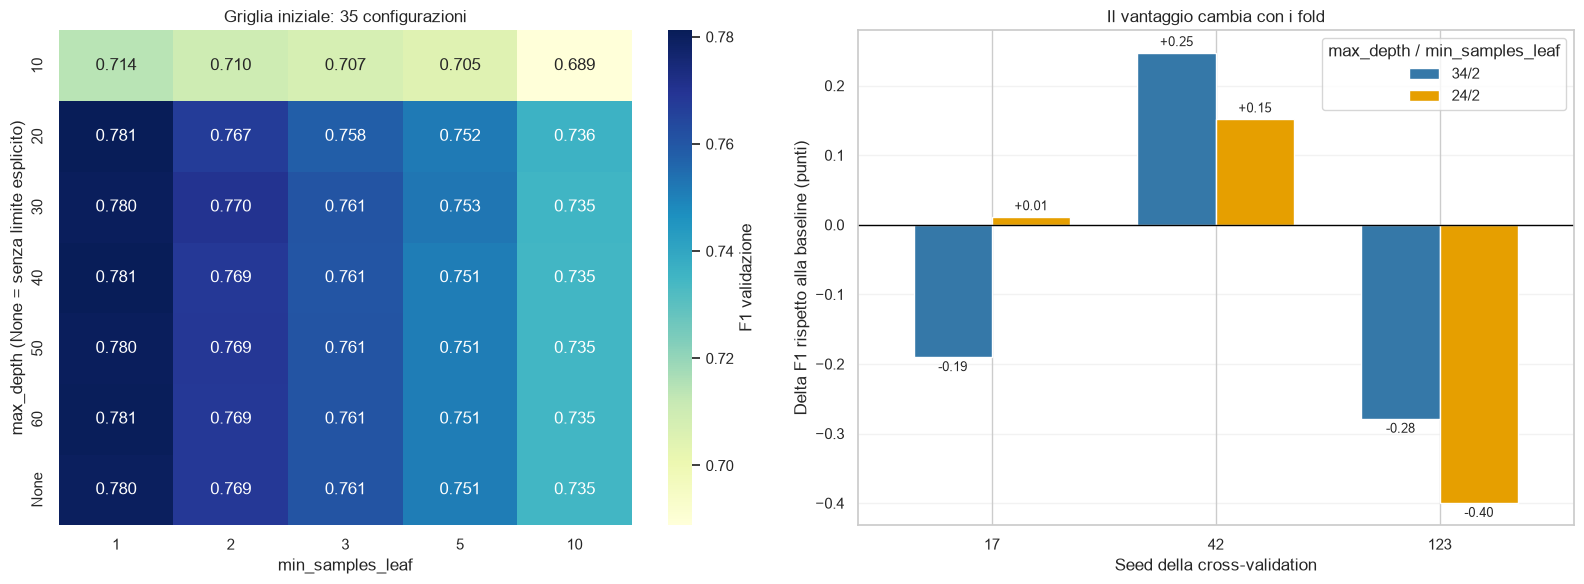

In [63]:
# VISUALIZZAZIONE DELLA RICERCA E DELLA SUA STABILITA.
# Sinistra: medie F1 della prima griglia; celle più scure indicano punteggi maggiori.
# Destra: differenza rispetto alla baseline con ciascun seed dei fold, in punti F1.
# Un valore negativo indica che il candidato ha F1 più basso della baseline in quella suddivisione.
import matplotlib.pyplot as plt
import seaborn as sns

fig_tuning_rf, assi_tuning_rf = plt.subplots(1, 2, figsize=(16, 6))
mappa_f1_rf = tabella_tuning_rf_iniziale.pivot(
    index='max_depth', columns='min_samples_leaf', values='F1 validazione',
).reindex(['10', '20', '30', '40', '50', '60', 'None'])
sns.heatmap(
    mappa_f1_rf, annot=True, fmt='.3f', cmap='YlGnBu',
    ax=assi_tuning_rf[0], cbar_kws={'label': 'F1 validazione'},
)
assi_tuning_rf[0].set_title('Griglia iniziale: 35 configurazioni')
assi_tuning_rf[0].set_xlabel('min_samples_leaf')
assi_tuning_rf[0].set_ylabel('max_depth (None = senza limite esplicito)')

# La sottrazione allinea i risultati per seed: confrontiamo sempre gli stessi fold.
f1_seed_rf = tabella_stabilita_completa_rf.pivot(
    index='Seed fold', columns='Modello', values='F1 validazione',
)
delta_seed_rf = f1_seed_rf[['Candidato scelto', 'Alternativa 24/2']].sub(
    f1_seed_rf['Baseline'], axis=0,
).mul(100).rename(columns={'Candidato scelto': '34/2', 'Alternativa 24/2': '24/2'})
delta_seed_rf.plot.bar(
    ax=assi_tuning_rf[1], rot=0, color=['#3578A8', '#E69F00'], width=0.7,
)
for gruppo_tuning_rf in assi_tuning_rf[1].containers:
    assi_tuning_rf[1].bar_label(
        gruppo_tuning_rf,
        labels=[f'{v:+.2f}' for v in gruppo_tuning_rf.datavalues],
        padding=3, fontsize=9,
    )
assi_tuning_rf[1].axhline(0, color='black', linewidth=1)
assi_tuning_rf[1].set_title('Il vantaggio cambia con i fold')
assi_tuning_rf[1].set_xlabel('Seed della cross-validation')
assi_tuning_rf[1].set_ylabel('Delta F1 rispetto alla baseline (punti)')
assi_tuning_rf[1].legend(title='max_depth / min_samples_leaf')
assi_tuning_rf[1].grid(axis='y', alpha=0.25)
assi_tuning_rf[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

## Risultato del tuning: miglioramento iniziale piccolo, non stabile

Sono state provate **41 configurazioni**: 35 combinazioni della griglia iniziale e 6 profondità intermedie. Restano fissi le colonne, il campione, lo split 80/20, i cinque fold originali, 300 alberi, random_state del classificatore, preprocessing e soglia di decisione. Nessun punteggio del test finale è stato usato.

La regola di selezione era: F1 medio di validazione maggiore della baseline **e** divario training-validazione minore; tra i candidati ammessi, F1 maggiore. Sui fold originali il vincitore è **max_depth=34, min_samples_leaf=2**: F1 passa da 0,7685 a 0,7710 e il gap da 11,01 a 10,60 punti. Il vantaggio compare in quattro fold su cinque ed è modesto, circa 0,25 punti F1.

Il massimo F1 assoluto della griglia è invece **max_depth=40, min_samples_leaf=1**, con F1 validazione 0,7812. Il suo F1 training è 0,9983 e il gap 21,71 punti: non soddisfa l'obiettivo di ridurre il sovradattamento.

### Controllo di stabilità

Il candidato 34/2 è stato mantenuto fisso e confrontato con la baseline anche cambiando il seed dei fold da 42 a 17 e 123. Poiché il vantaggio non regge, è stato controllato anche 24/2, un compromesso con minore divario. Le medie delle tre suddivisioni sono:

| Configurazione | F1 training | F1 validazione | Gap F1 |
|---|---:|---:|---:|
| Baseline: None / 2 | 0,8782 | 0,7690 | 10,91 punti |
| Candidato: 34 / 2 | 0,8770 | 0,7683 | 10,87 punti |
| Alternativa: 24 / 2 | 0,8667 | 0,7682 | 9,85 punti |

**Non emerge un miglioramento stabile di entrambi gli obiettivi nei candidati verificati.** Il candidato 34/2 rende leggermente peggio della baseline con entrambi i nuovi seed. La coppia 24/2 riduce maggiormente il divario, con F1 medio leggermente inferiore e comunque molto simile alla baseline.

La foresta originale resta quindi il riferimento: **max_depth=None, min_samples_leaf=2**. Il candidato 34/2 è disponibile separatamente come `modello_rf_candidato_34`, senza sostituire `modello_rf`. I risultati completi delle 41 prove restano in `tabella_tuning_rf` e `cv_tuning_rf`; il confronto delle tre suddivisioni è in `tabella_stabilita_completa_rf`.

Queste suddivisioni riutilizzano gli stessi dati di training: sono controlli di stabilità, non tre test indipendenti. Il massimo F1 dopo una ricerca può essere ottimistico e il piccolo guadagno sui fold di selezione non garantisce un vantaggio futuro. I controlli per profili coincidenti e nel tempo restano valutazioni distinte. L'overfitting osservato non è stato eliminato.

In [64]:
# ALTRI PARAMETRI DELLA RANDOM FOREST: PROVE CONTROLLATE.
# Lo scopo resta migliorare F1 di validazione e diminuire il gap rispetto alla baseline.
# Conserviamo dati, colonne, preprocessing, seed del classificatore e cinque fold originali.
# Ogni prova modifica soltanto i parametri indicati nel suo dizionario.
# Il test finale non viene utilizzato.
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_validate, StratifiedKFold

# Tre dizionari separati conservano: sintesi, cinque punteggi per metrica e parametri modificati.
# Rieseguire questa cella azzera la nuova ricerca; i risultati delle ricerche precedenti restano separati.
risultati_extra_rf = {}
punteggi_extra_rf = {}
parametri_extra_rf = {}
metriche_extra_rf = {
    'f1': 'f1', 'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
}

def prova_extra_rf(nome, parametri):
    # Se la stessa prova è già stata eseguita in questa ricerca, riusiamo i risultati.
    # Il controllo sul dizionario evita sia righe duplicate sia addestramenti ripetuti inutilmente.
    if nome in punteggi_extra_rf and parametri_extra_rf[nome] == parametri:
        return risultati_extra_rf[nome]
    inizio_extra_rf = time.perf_counter()

    # Il prefisso classificatore__ serve per modificare il classificatore dentro la pipeline.
    # clone mantiene le impostazioni della baseline, senza copiarne l'apprendimento.
    pipeline_extra_rf = clone(modello_rf).set_params(**{
        'classificatore__' + chiave: valore for chiave, valore in parametri.items()
    })
    score_extra_rf = cross_validate(
        pipeline_extra_rf, X_train, y_train, cv=fold,
        scoring=metriche_extra_rf, return_train_score=True,
        n_jobs=1, error_score='raise',
    )

    # 'test_f1' è il punteggio del fold di validazione, non del test finale.
    # Il gap è la differenza appaiata tra training e validazione, espressa in punti F1.
    riga_extra_rf = {
        'Variante': nome,
        'F1 training': score_extra_rf['train_f1'].mean(),
        'F1 validazione': score_extra_rf['test_f1'].mean(),
        'Gap F1 (punti)': (score_extra_rf['train_f1'] - score_extra_rf['test_f1']).mean() * 100,
        'Precision validazione': score_extra_rf['test_precision'].mean(),
        'Recall validazione': score_extra_rf['test_recall'].mean(),
        'Accuracy validazione': score_extra_rf['test_accuracy'].mean(),
        'Std F1 validazione': score_extra_rf['test_f1'].std(),
        'Secondi': time.perf_counter() - inizio_extra_rf,
    }
    risultati_extra_rf[nome] = riga_extra_rf
    punteggi_extra_rf[nome] = score_extra_rf
    parametri_extra_rf[nome] = dict(parametri)
    print(nome, 'F1:', round(riga_extra_rf['F1 validazione'], 4),
          'gap:', round(riga_extra_rf['Gap F1 (punti)'], 2),
          'secondi:', round(riga_extra_rf['Secondi'], 1), flush=True)
    return riga_extra_rf

# FASE 1A: colonne candidate a ogni divisione e campionamento delle righe.
# max_features è applicato alle colonne DOPO l'encoding: un paese può generare molte colonne.
# 'sqrt' è la baseline; 'log2' prova meno colonne; le frazioni ne provano una quota.
# 1.0 float indica tutte le colonne, mentre 1 intero indicherebbe una sola colonna.
# max_samples riduce le estrazioni bootstrap di ogni albero: con 0.5 usiamo metà delle estrazioni.
# Le estrazioni avvengono con rimpiazzo, quindi non coincidono con il numero di righe uniche.
# bootstrap rimane True, condizione necessaria per usare max_samples.
prove_colonne_righe_rf = [
    ('Baseline extra', {}),
    ('max_features=log2', {'max_features': 'log2'}),
    ('max_features=0.15', {'max_features': 0.15}),
    ('max_features=0.3', {'max_features': 0.3}),
    ('max_features=0.5', {'max_features': 0.5}),
    ('max_features=1.0', {'max_features': 1.0}),
    ('max_samples=0.5', {'max_samples': 0.5}),
    ('max_samples=0.7', {'max_samples': 0.7}),
    ('max_samples=0.9', {'max_samples': 0.9}),
]
for nome_prova_rf, parametri_prova_rf in prove_colonne_righe_rf:
    prova_extra_rf(nome_prova_rf, parametri_prova_rf)

tabella_extra_rf = pd.DataFrame(list(risultati_extra_rf.values())).set_index('Variante')
display(tabella_extra_rf.sort_values('F1 validazione', ascending=False).round(4))

Baseline extra F1: 0.7685 gap: 11.01 secondi: 5.1
max_features=log2 F1: 0.7361 gap: 8.85 secondi: 4.5
max_features=0.15 F1: 0.7837 gap: 13.8 secondi: 5.7
max_features=0.3 F1: 0.7884 gap: 16.72 secondi: 7.3
max_features=0.5 F1: 0.7861 gap: 18.16 secondi: 9.1
max_features=1.0 F1: 0.7827 gap: 19.15 secondi: 14.3
max_samples=0.5 F1: 0.761 gap: 7.52 secondi: 4.1
max_samples=0.7 F1: 0.768 gap: 8.9 secondi: 4.3
max_samples=0.9 F1: 0.7686 gap: 10.45 secondi: 4.7


,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Std F1 validazione,Secondi
Variante,,,,,,,,
max_features=0.3,0.9557,0.7884,16.7245,0.8318,0.7497,0.8483,0.0189,7.2984
max_features=0.5,0.9677,0.7861,18.1559,0.8252,0.7508,0.8459,0.0186,9.1079
max_features=0.15,0.9217,0.7837,13.7971,0.8422,0.7331,0.8475,0.0194,5.7212
max_features=1.0,0.9742,0.7827,19.1470,0.8201,0.7488,0.8432,0.0167,14.3242
max_samples=0.9,0.8730,0.7686,10.4461,0.8578,0.6964,0.8419,0.0155,4.6862
Baseline extra,0.8786,0.7685,11.0117,0.8573,0.6967,0.8418,0.0165,5.1446
max_samples=0.7,0.8570,0.7680,8.8994,0.8602,0.6939,0.8420,0.0192,4.3391
max_samples=0.5,0.8362,0.7610,7.5164,0.8593,0.6831,0.8382,0.0152,4.1080
max_features=log2,0.8246,0.7361,8.8495,0.8886,0.6285,0.8301,0.0177,4.5415


In [65]:
# FASE 1B: ALTRI PARAMETRI, ANCORA UNO ALLA VOLTA RISPETTO ALLA BASELINE.
# min_samples_split richiede più esempi per poter dividere un nodo.
# ccp_alpha applica una potatura: valori maggiori penalizzano alberi più complessi.
# max_leaf_nodes limita il numero totale di foglie con cui l'albero può descrivere i dati.
# criterion cambia come si valuta la qualità di una divisione; proviamo entropy oltre al gini di base.
# log_loss non è una prova separata: in questo classificatore usa anch'esso l'entropia di Shannon.
# class_weight dà più peso alla classe meno frequente e può cambiare il rapporto precision/recall.
# balanced_subsample ricalcola quei pesi per il campione bootstrap del singolo albero.
# Aumentare n_estimators serve soprattutto a stabilizzare la media degli alberi:
# non è di per sé una limitazione della complessità di ogni albero.
prove_vincoli_rf = [
    ('min_samples_split=10', {'min_samples_split': 10}),
    ('min_samples_split=30', {'min_samples_split': 30}),
    ('min_samples_split=60', {'min_samples_split': 60}),
    ('ccp_alpha=0.0001', {'ccp_alpha': 0.0001}),
    ('ccp_alpha=0.0005', {'ccp_alpha': 0.0005}),
    ('ccp_alpha=0.001', {'ccp_alpha': 0.001}),
    ('max_leaf_nodes=100', {'max_leaf_nodes': 100}),
    ('max_leaf_nodes=300', {'max_leaf_nodes': 300}),
    ('max_leaf_nodes=600', {'max_leaf_nodes': 600}),
    ('criterion=entropy', {'criterion': 'entropy'}),
    ('class_weight=balanced', {'class_weight': 'balanced'}),
    ('class_weight=balanced_subsample', {'class_weight': 'balanced_subsample'}),
    ('n_estimators=600', {'n_estimators': 600}),
]
for nome_prova_rf, parametri_prova_rf in prove_vincoli_rf:
    prova_extra_rf(nome_prova_rf, parametri_prova_rf)

tabella_extra_rf = pd.DataFrame(list(risultati_extra_rf.values())).set_index('Variante')
baseline_extra_rf = tabella_extra_rf.loc['Baseline extra']
tabella_extra_rf['Delta F1 (punti)'] = (
    tabella_extra_rf['F1 validazione'] - baseline_extra_rf['F1 validazione']) * 100
tabella_extra_rf['Delta gap (punti)'] = (
    tabella_extra_rf['Gap F1 (punti)'] - baseline_extra_rf['Gap F1 (punti)'])
print('Screening completato:', len(tabella_extra_rf), 'configurazioni, baseline inclusa.')
print('F1 più alto è desiderabile; un delta gap negativo indica un divario più basso della baseline.')
display(tabella_extra_rf.sort_values('F1 validazione', ascending=False).round(4))

min_samples_split=10 F1: 0.7678 gap: 8.54 secondi: 4.5
min_samples_split=30 F1: 0.7571 gap: 5.95 secondi: 4.4
min_samples_split=60 F1: 0.7538 gap: 3.88 secondi: 4.0
ccp_alpha=0.0001 F1: 0.7661 gap: 9.89 secondi: 4.8
ccp_alpha=0.0005 F1: 0.748 gap: 3.1 secondi: 4.9
ccp_alpha=0.001 F1: 0.7145 gap: 2.12 secondi: 4.8
max_leaf_nodes=100 F1: 0.7352 gap: 3.84 secondi: 3.9
max_leaf_nodes=300 F1: 0.7588 gap: 7.36 secondi: 4.4
max_leaf_nodes=600 F1: 0.7658 gap: 10.79 secondi: 4.7
criterion=entropy F1: 0.7715 gap: 11.06 secondi: 4.8
class_weight=balanced F1: 0.79 gap: 11.61 secondi: 5.0
class_weight=balanced_subsample F1: 0.7865 gap: 11.78 secondi: 6.7
n_estimators=600 F1: 0.7719 gap: 10.68 secondi: 9.7
Screening completato: 22 configurazioni, baseline inclusa.
F1 più alto è desiderabile; un delta gap negativo indica un divario più basso della baseline.


,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Std F1 validazione,Secondi,Delta F1 (punti),Delta gap (punti)
Variante,,,,,,,,,,
class_weight=balanced,0.9061,0.7900,11.6114,0.7940,0.7864,0.8424,0.0164,5.0204,2.1510,0.5996
max_features=0.3,0.9557,0.7884,16.7245,0.8318,0.7497,0.8483,0.0189,7.2984,1.9943,5.7127
class_weight=balanced_subsample,0.9044,0.7865,11.7847,0.8068,0.7673,0.8429,0.0187,6.7003,1.8024,0.7730
max_features=0.5,0.9677,0.7861,18.1559,0.8252,0.7508,0.8459,0.0186,9.1079,1.7595,7.1441
max_features=0.15,0.9217,0.7837,13.7971,0.8422,0.7331,0.8475,0.0194,5.7212,1.5231,2.7853
max_features=1.0,0.9742,0.7827,19.1470,0.8201,0.7488,0.8432,0.0167,14.3242,1.4240,8.1353
n_estimators=600,0.8787,0.7719,10.6827,0.8581,0.7016,0.8436,0.0163,9.6667,0.3387,-0.3291
criterion=entropy,0.8821,0.7715,11.0576,0.8536,0.7041,0.8428,0.0163,4.7979,0.3038,0.0459
max_samples=0.9,0.8730,0.7686,10.4461,0.8578,0.6964,0.8419,0.0155,4.6862,0.0083,-0.5657


In [66]:
# FASE 2: COMBINARE I PARAMETRI CHE HANNO MOSTRATO EFFETTI COMPLEMENTARI.
# max_features più alto ha aumentato F1, ma anche il gap.
# Foglie da cinque esempi e max_samples=0.7 provano a limitare la complessità.
# class_weight='balanced' ha migliorato F1: controlliamo se mantiene il vantaggio nelle combinazioni.
# Il confronto cambia più parametri insieme: misura la configurazione complessiva,
# senza attribuire il risultato a una singola modifica.
from itertools import product

prove_combinate_rf = []
for feature_rf, foglia_rf, campione_rf, peso_rf in product(
    [0.15, 0.3], [2, 5], [None, 0.7], [None, 'balanced']
):
    # Queste due configurazioni sono già presenti nello screening come prove di max_features.
    if foglia_rf == 2 and campione_rf is None and peso_rf is None:
        continue
    nome_combinazione_rf = (
        f'COMBO f={feature_rf}, leaf={foglia_rf}, sample={campione_rf}, weight={peso_rf}'
    )
    prove_combinate_rf.append((nome_combinazione_rf, {
        'max_features': feature_rf,
        'min_samples_leaf': foglia_rf,
        'max_samples': campione_rf,
        'class_weight': peso_rf,
    }))

# Controlliamo anche se bastano pesi bilanciati e campionamento ridotto,
# conservando max_features='sqrt' e min_samples_leaf=2 della baseline.
for campione_rf in [0.5, 0.7, 0.9]:
    prove_combinate_rf.append((
        f'COMBO balanced, sample={campione_rf}',
        {'class_weight': 'balanced', 'max_samples': campione_rf},
    ))
prove_combinate_rf.append((
    'COMBO balanced, split=10',
    {'class_weight': 'balanced', 'min_samples_split': 10},
))
print('Nuove combinazioni mirate:', len(prove_combinate_rf), flush=True)
for nome_prova_rf, parametri_prova_rf in prove_combinate_rf:
    prova_extra_rf(nome_prova_rf, parametri_prova_rf)

tabella_extra_rf = pd.DataFrame(list(risultati_extra_rf.values())).set_index('Variante')
baseline_extra_rf = tabella_extra_rf.loc['Baseline extra']
tabella_extra_rf['Delta F1 (punti)'] = (
    tabella_extra_rf['F1 validazione'] - baseline_extra_rf['F1 validazione']) * 100
tabella_extra_rf['Delta gap (punti)'] = (
    tabella_extra_rf['Gap F1 (punti)'] - baseline_extra_rf['Gap F1 (punti)'])

# Criterio stabilito: prima rispettare entrambi gli obiettivi, poi massimizzare F1 di validazione.
# Una differenza del solo arrotondamento non deve essere considerata un miglioramento.
ammessi_extra_rf = tabella_extra_rf.loc[
    (tabella_extra_rf['F1 validazione'] > baseline_extra_rf['F1 validazione'] + 1e-12) &
    (tabella_extra_rf['Gap F1 (punti)'] < baseline_extra_rf['Gap F1 (punti)'] - 1e-12)
].sort_values(['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True])
print('Configurazioni complessive:', len(tabella_extra_rf))
print('Dieci F1 di validazione più alti, senza vincolo sul gap:')
display(tabella_extra_rf.sort_values('F1 validazione', ascending=False).head(10).round(4))
print('Candidati con F1 più alto E gap più basso della baseline:')
display(ammessi_extra_rf.head(10).round(4))

Nuove combinazioni mirate: 18
COMBO f=0.15, leaf=2, sample=None, weight=balanced F1: 0.7941 gap: 14.29 secondi: 6.1
COMBO f=0.15, leaf=2, sample=0.7, weight=None F1: 0.7816 gap: 11.26 secondi: 5.1
COMBO f=0.15, leaf=2, sample=0.7, weight=balanced F1: 0.792 gap: 12.08 secondi: 8.9
COMBO f=0.15, leaf=5, sample=None, weight=None F1: 0.7732 gap: 5.93 secondi: 10.9
COMBO f=0.15, leaf=5, sample=None, weight=balanced F1: 0.7849 gap: 7.17 secondi: 9.9
COMBO f=0.15, leaf=5, sample=0.7, weight=None F1: 0.7741 gap: 4.53 secondi: 8.7
COMBO f=0.15, leaf=5, sample=0.7, weight=balanced F1: 0.7854 gap: 5.66 secondi: 8.9
COMBO f=0.3, leaf=2, sample=None, weight=balanced F1: 0.7961 gap: 16.49 secondi: 16.5
COMBO f=0.3, leaf=2, sample=0.7, weight=None F1: 0.7895 gap: 13.46 secondi: 13.6
COMBO f=0.3, leaf=2, sample=0.7, weight=balanced F1: 0.7919 gap: 14.29 secondi: 14.1
COMBO f=0.3, leaf=5, sample=None, weight=None F1: 0.7803 gap: 7.98 secondi: 13.8
COMBO f=0.3, leaf=5, sample=None, weight=balanced F1: 0

,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Std F1 validazione,Secondi,Delta F1 (punti),Delta gap (punti)
Variante,,,,,,,,,,
"COMBO f=0.3, leaf=2, sample=None, weight=balanced",0.9611,0.7961,16.4934,0.7897,0.8029,0.8449,0.0148,16.4673,2.7646,5.4816
"COMBO f=0.15, leaf=2, sample=None, weight=balanced",0.9370,0.7941,14.2904,0.7918,0.7966,0.8442,0.0127,6.0630,2.5599,3.2787
"COMBO f=0.15, leaf=2, sample=0.7, weight=balanced",0.9129,0.7920,12.0826,0.7875,0.7969,0.8422,0.0156,8.9465,2.3543,1.0709
"COMBO f=0.3, leaf=2, sample=0.7, weight=balanced",0.9348,0.7919,14.2946,0.7829,0.8013,0.8411,0.0141,14.0864,2.3395,3.2829
"COMBO balanced, sample=0.9",0.9008,0.7907,11.0090,0.7911,0.7905,0.8422,0.0152,8.2555,2.2197,-0.0027
class_weight=balanced,0.9061,0.7900,11.6114,0.7940,0.7864,0.8424,0.0164,5.0204,2.1510,0.5996
"COMBO f=0.3, leaf=2, sample=0.7, weight=None",0.9240,0.7895,13.4566,0.8334,0.7502,0.8492,0.0195,13.5715,2.0980,2.4449
max_features=0.3,0.9557,0.7884,16.7245,0.8318,0.7497,0.8483,0.0189,7.2984,1.9943,5.7127
"COMBO balanced, split=10",0.8831,0.7881,9.5011,0.7878,0.7886,0.8401,0.0169,5.8889,1.9602,-1.5107


Candidati con F1 più alto E gap più basso della baseline:


,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Std F1 validazione,Secondi,Delta F1 (punti),Delta gap (punti)
Variante,,,,,,,,,,
"COMBO balanced, sample=0.9",0.9008,0.7907,11.0090,0.7911,0.7905,0.8422,0.0152,8.2555,2.2197,-0.0027
"COMBO balanced, split=10",0.8831,0.7881,9.5011,0.7878,0.7886,0.8401,0.0169,5.8889,1.9602,-1.5107
"COMBO f=0.3, leaf=5, sample=None, weight=balanced",0.8781,0.7873,9.0793,0.7768,0.7982,0.8373,0.0150,8.5880,1.8790,-1.9324
"COMBO balanced, sample=0.7",0.8866,0.7871,9.9484,0.7893,0.7853,0.8399,0.0177,21.0307,1.8594,-1.0633
"COMBO f=0.15, leaf=5, sample=0.7, weight=balanced",0.8420,0.7854,5.6581,0.7817,0.7894,0.8374,0.0158,8.9031,1.6915,-5.3537
"COMBO balanced, sample=0.5",0.8681,0.7851,8.3014,0.7863,0.7842,0.8382,0.0189,12.9041,1.6604,-2.7104
"COMBO f=0.3, leaf=5, sample=0.7, weight=balanced",0.8615,0.7850,7.6564,0.7749,0.7955,0.8356,0.0148,19.6338,1.6479,-3.3554
"COMBO f=0.15, leaf=5, sample=None, weight=balanced",0.8567,0.7849,7.1728,0.7798,0.7902,0.8367,0.0141,9.8507,1.6441,-3.8389
"COMBO f=0.3, leaf=5, sample=None, weight=None",0.8601,0.7803,7.9775,0.8291,0.7372,0.8435,0.0205,13.8364,1.1835,-3.0343


In [67]:
# FASE 3: FINALISTI FISSATI PRIMA DEL CONTROLLO SU ALTRI FOLD.
# Prendiamo i primi tre candidati ammessi per F1 e un candidato più regolarizzato:
# tra quelli entro 0.01 F1 dal massimo ammesso, scegliamo il gap più piccolo.
# 0.01 corrisponde a un punto sulla scala percentuale dell'F1.
# Questa regola conserva sia candidati con F1 alto sia un compromesso con divario più basso.
nomi_finalisti_extra_rf = ammessi_extra_rf.index[:3].tolist()
fascia_extra_rf = ammessi_extra_rf.loc[
    ammessi_extra_rf['F1 validazione'] >= ammessi_extra_rf['F1 validazione'].max() - 0.01
]
nome_prudente_extra_rf = fascia_extra_rf['Gap F1 (punti)'].idxmin()
if nome_prudente_extra_rf not in nomi_finalisti_extra_rf:
    nomi_finalisti_extra_rf.append(nome_prudente_extra_rf)
nomi_controllo_extra_rf = ['Baseline extra'] + nomi_finalisti_extra_rf
print('Finalisti fissati:')
for nome_finalista_extra_rf in nomi_finalisti_extra_rf:
    print(nome_finalista_extra_rf, parametri_extra_rf[nome_finalista_extra_rf], flush=True)

# Usiamo lo stesso train di 9.600 righe, cambiando soltanto gli indici dei cinque fold.
# Seed 42: riusiamo i punteggi già calcolati. Seed 17 e 123: nuovi addestramenti sugli altri split.
# Anche i nuovi fold fanno parte della valutazione sul training: non sono test indipendenti.
righe_stabilita_extra_rf = []
punteggi_stabilita_extra_rf = {}
for seme_extra_rf in [42, 17, 123]:
    fold_controllo_extra_rf = (
        fold if seme_extra_rf == 42 else list(StratifiedKFold(
            n_splits=5, shuffle=True, random_state=seme_extra_rf
        ).split(X_train, y_train))
    )
    for nome_controllo_extra_rf in nomi_controllo_extra_rf:
        if seme_extra_rf == 42:
            score_controllo_extra_rf = punteggi_extra_rf[nome_controllo_extra_rf]
        else:
            print('Stabilità:', seme_extra_rf, nome_controllo_extra_rf, flush=True)
            pipeline_controllo_extra_rf = clone(modello_rf).set_params(**{
                'classificatore__' + k: v
                for k, v in parametri_extra_rf[nome_controllo_extra_rf].items()
            })
            score_controllo_extra_rf = cross_validate(
                pipeline_controllo_extra_rf, X_train, y_train,
                cv=fold_controllo_extra_rf, scoring=metriche_extra_rf,
                return_train_score=True, n_jobs=1, error_score='raise',
            )
        punteggi_stabilita_extra_rf[(seme_extra_rf, nome_controllo_extra_rf)] = score_controllo_extra_rf
        righe_stabilita_extra_rf.append({
            'Seed fold': seme_extra_rf,
            'Variante': nome_controllo_extra_rf,
            'F1 training': score_controllo_extra_rf['train_f1'].mean(),
            'F1 validazione': score_controllo_extra_rf['test_f1'].mean(),
            'Gap F1 (punti)': (
                score_controllo_extra_rf['train_f1'] - score_controllo_extra_rf['test_f1']).mean() * 100,
            'Precision validazione': score_controllo_extra_rf['test_precision'].mean(),
            'Recall validazione': score_controllo_extra_rf['test_recall'].mean(),
            'Accuracy validazione': score_controllo_extra_rf['test_accuracy'].mean(),
        })

stabilita_extra_rf = pd.DataFrame(righe_stabilita_extra_rf)
riepilogo_extra_rf = stabilita_extra_rf.groupby('Variante', sort=False)[[
    'F1 training', 'F1 validazione', 'Gap F1 (punti)',
    'Precision validazione', 'Recall validazione', 'Accuracy validazione',
]].mean()

# Verifichiamo quante suddivisioni migliorano F1 e quante riducono il gap.
# Non basta un gap piccolo da solo: potrebbe essere un modello che impara troppo poco.
f1_semi_extra_rf = stabilita_extra_rf.pivot(
    index='Seed fold', columns='Variante', values='F1 validazione')
gap_semi_extra_rf = stabilita_extra_rf.pivot(
    index='Seed fold', columns='Variante', values='Gap F1 (punti)')
riepilogo_extra_rf['Seed con F1 migliore'] = f1_semi_extra_rf.gt(
    f1_semi_extra_rf['Baseline extra'] + 1e-12, axis=0).sum()
riepilogo_extra_rf['Seed con gap minore'] = gap_semi_extra_rf.lt(
    gap_semi_extra_rf['Baseline extra'] - 1e-12, axis=0).sum()

# Per scegliere richiediamo che entrambi i vantaggi siano presenti in tutte e tre le suddivisioni.
# Fra i candidati coerenti scegliamo F1 medio maggiore, usando il gap per sciogliere eventuali parità.
ammessi_stabili_extra_rf = riepilogo_extra_rf.loc[
    (riepilogo_extra_rf['Seed con F1 migliore'] == 3) &
    (riepilogo_extra_rf['Seed con gap minore'] == 3)
].sort_values(['F1 validazione', 'Gap F1 (punti)'], ascending=[False, True])
nome_scelto_extra_rf = (
    ammessi_stabili_extra_rf.index[0] if not ammessi_stabili_extra_rf.empty else 'Baseline extra'
)
print('Medie sui tre seed, ciascuno con cinque fold:')
display(riepilogo_extra_rf.round(4))
print('F1 per suddivisione:')
display(f1_semi_extra_rf.round(4))
print('Gap per suddivisione:')
display(gap_semi_extra_rf.round(4))
print('Scelta dopo il controllo:', nome_scelto_extra_rf)
print('Le suddivisioni riusano gli stessi dati: il test finale rimane escluso.')

Finalisti fissati:
COMBO balanced, sample=0.9 {'class_weight': 'balanced', 'max_samples': 0.9}
COMBO balanced, split=10 {'class_weight': 'balanced', 'min_samples_split': 10}
COMBO f=0.3, leaf=5, sample=None, weight=balanced {'max_features': 0.3, 'min_samples_leaf': 5, 'max_samples': None, 'class_weight': 'balanced'}
COMBO f=0.15, leaf=5, sample=0.7, weight=balanced {'max_features': 0.15, 'min_samples_leaf': 5, 'max_samples': 0.7, 'class_weight': 'balanced'}
Stabilità: 17 Baseline extra
Stabilità: 17 COMBO balanced, sample=0.9
Stabilità: 17 COMBO balanced, split=10
Stabilità: 17 COMBO f=0.3, leaf=5, sample=None, weight=balanced
Stabilità: 17 COMBO f=0.15, leaf=5, sample=0.7, weight=balanced
Stabilità: 123 Baseline extra
Stabilità: 123 COMBO balanced, sample=0.9
Stabilità: 123 COMBO balanced, split=10
Stabilità: 123 COMBO f=0.3, leaf=5, sample=None, weight=balanced
Stabilità: 123 COMBO f=0.15, leaf=5, sample=0.7, weight=balanced
Medie sui tre seed, ciascuno con cinque fold:


,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Seed con F1 migliore,Seed con gap minore
Variante,,,,,,,,
Baseline extra,0.8782,0.7690,10.9147,0.8597,0.6958,0.8423,0,0
"COMBO balanced, sample=0.9",0.9001,0.7923,10.7748,0.7948,0.7901,0.8438,3,3
"COMBO balanced, split=10",0.8819,0.7889,9.2940,0.7896,0.7886,0.8408,3,3
"COMBO f=0.3, leaf=5, sample=None, weight=balanced",0.8783,0.7898,8.8454,0.7805,0.7996,0.8394,3,3
"COMBO f=0.15, leaf=5, sample=0.7, weight=balanced",0.8411,0.7871,5.4014,0.7819,0.7925,0.8382,3,3


F1 per suddivisione:


Variante,Baseline extra,"COMBO balanced, sample=0.9","COMBO balanced, split=10","COMBO f=0.15, leaf=5, sample=0.7, weight=balanced","COMBO f=0.3, leaf=5, sample=None, weight=balanced"
Seed fold,,,,,
17,0.7678,0.7935,0.7894,0.7880,0.7896
42,0.7685,0.7907,0.7881,0.7854,0.7873
123,0.7707,0.7928,0.7893,0.7878,0.7926


Gap per suddivisione:


Variante,Baseline extra,"COMBO balanced, sample=0.9","COMBO balanced, split=10","COMBO f=0.15, leaf=5, sample=0.7, weight=balanced","COMBO f=0.3, leaf=5, sample=None, weight=balanced"
Seed fold,,,,,
17,10.9286,10.6746,9.1386,5.1886,8.8465
42,11.0117,11.0090,9.5011,5.6581,9.0793
123,10.8037,10.6407,9.2423,5.3576,8.6103


Scelta dopo il controllo: COMBO balanced, sample=0.9
Le suddivisioni riusano gli stessi dati: il test finale rimane escluso.


In [68]:
# DUE RISULTATI DISTINTI: MASSIMO F1 E COMPROMESSO CON MENO SOVRADATTAMENTO.
# La regola precedente massimizza F1 fra i candidati che migliorano entrambi gli obiettivi.
# Il candidato prudente era stato fissato prima del controllo sugli altri seed.
# Non li confondiamo: il massimo F1 riduce il gap di poco, mentre il prudente lo riduce molto di più.
nome_massimo_f1_extra_rf = nome_scelto_extra_rf
nome_compromesso_extra_rf = (
    nome_prudente_extra_rf if nome_prudente_extra_rf in ammessi_stabili_extra_rf.index
    else nome_scelto_extra_rf
)
parametri_massimo_f1_extra_rf = dict(parametri_extra_rf[nome_massimo_f1_extra_rf])
parametri_compromesso_extra_rf = dict(parametri_extra_rf[nome_compromesso_extra_rf])
print('Massimo F1 tra i candidati coerenti:', parametri_massimo_f1_extra_rf)
print('Compromesso con minore divario:', parametri_compromesso_extra_rf)

# Fit finale sul solo training: prepara due pipeline da riutilizzare.
# Non costituisce una nuova valutazione e non produce punteggi del test finale.
# La foresta originale modello_rf rimane disponibile come baseline.
modello_rf_miglior_f1 = clone(modello_rf).set_params(**{
    'classificatore__' + k: v for k, v in parametri_massimo_f1_extra_rf.items()
})
modello_rf_miglior_f1.fit(X_train, y_train)

modello_rf_meno_overfitting = clone(modello_rf).set_params(**{
    'classificatore__' + k: v for k, v in parametri_compromesso_extra_rf.items()
})
modello_rf_meno_overfitting.fit(X_train, y_train)

# Come proposta generale per i due obiettivi scegliamo il compromesso prudente:
# perde poco F1 rispetto al massimo, mantenendo un divario molto più piccolo.
modello_rf_migliorato = modello_rf_meno_overfitting

nomi_riepilogo_finale_extra_rf = [
    'Baseline extra', nome_massimo_f1_extra_rf, nome_compromesso_extra_rf,
]
confronto_finale_extra_rf = riepilogo_extra_rf.loc[nomi_riepilogo_finale_extra_rf].copy()
confronto_finale_extra_rf.index = ['Baseline', 'Massimo F1', 'Compromesso prudente']
display(confronto_finale_extra_rf.round(4))

# Verifichiamo anche quanti confronti appaiati di singolo fold sono positivi.
# I 15 confronti riutilizzano le stesse righe: non sono 15 test indipendenti.
for nome_verifica_extra_rf in [nome_massimo_f1_extra_rf, nome_compromesso_extra_rf]:
    delta_fold_extra_rf = np.concatenate([
        punteggi_stabilita_extra_rf[(s, nome_verifica_extra_rf)]['test_f1'] -
        punteggi_stabilita_extra_rf[(s, 'Baseline extra')]['test_f1']
        for s in [42, 17, 123]
    ])
    print(nome_verifica_extra_rf, '- F1 maggiore in',
          int((delta_fold_extra_rf > 0).sum()), 'dei', len(delta_fold_extra_rf), 'fold')
print('Pipeline pronta: modello_rf_migliorato. Alternativa: modello_rf_miglior_f1.')
print('Baseline e test finale non sono stati modificati.')

Massimo F1 tra i candidati coerenti: {'class_weight': 'balanced', 'max_samples': 0.9}
Compromesso con minore divario: {'max_features': 0.15, 'min_samples_leaf': 5, 'max_samples': 0.7, 'class_weight': 'balanced'}


,F1 training,F1 validazione,Gap F1 (punti),Precision validazione,Recall validazione,Accuracy validazione,Seed con F1 migliore,Seed con gap minore
Baseline,0.8782,0.7690,10.9147,0.8597,0.6958,0.8423,0,0
Massimo F1,0.9001,0.7923,10.7748,0.7948,0.7901,0.8438,3,3
Compromesso prudente,0.8411,0.7871,5.4014,0.7819,0.7925,0.8382,3,3


COMBO balanced, sample=0.9 - F1 maggiore in 15 dei 15 fold
COMBO f=0.15, leaf=5, sample=0.7, weight=balanced - F1 maggiore in 15 dei 15 fold
Pipeline pronta: modello_rf_migliorato. Alternativa: modello_rf_miglior_f1.
Baseline e test finale non sono stati modificati.


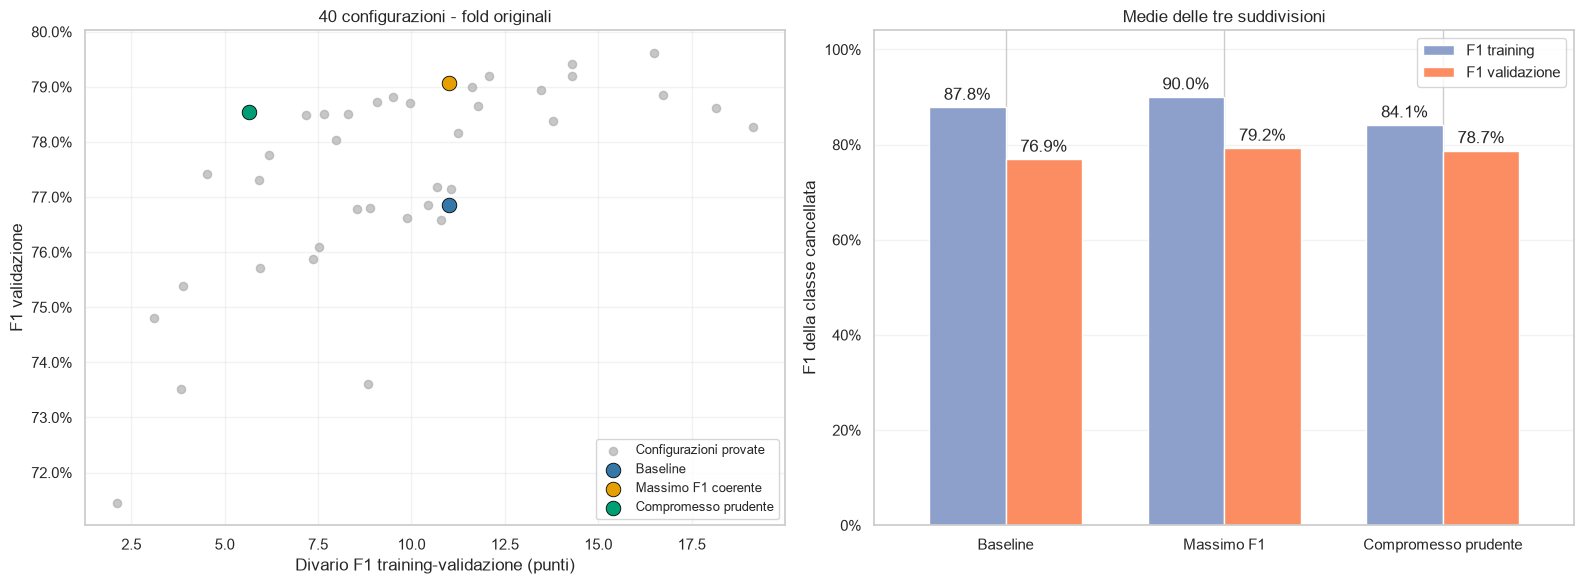

In [69]:
# GRAFICI DELLA NUOVA RICERCA.
# A sinistra ogni punto è una configurazione misurata sui fold originali.
# Il compromesso desiderabile va verso l'alto (più F1) e verso sinistra (meno divario).
# A destra confrontiamo training e validazione medi sui tre seed, ciascuno con cinque fold.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig_extra_rf, assi_extra_rf = plt.subplots(1, 2, figsize=(16, 6))
assi_extra_rf[0].scatter(
    tabella_extra_rf['Gap F1 (punti)'], tabella_extra_rf['F1 validazione'],
    color='#AAAAAA', alpha=0.65, s=35, label='Configurazioni provate',
)
for nome_punto_extra_rf, etichetta_punto_extra_rf, colore_punto_extra_rf in [
    ('Baseline extra', 'Baseline', '#3578A8'),
    (nome_massimo_f1_extra_rf, 'Massimo F1 coerente', '#E69F00'),
    (nome_compromesso_extra_rf, 'Compromesso prudente', '#009E73'),
]:
    riga_punto_extra_rf = tabella_extra_rf.loc[nome_punto_extra_rf]
    assi_extra_rf[0].scatter(
        riga_punto_extra_rf['Gap F1 (punti)'], riga_punto_extra_rf['F1 validazione'],
        color=colore_punto_extra_rf, s=110, edgecolor='black',
        linewidth=0.6, label=etichetta_punto_extra_rf, zorder=3,
    )
assi_extra_rf[0].set_title('40 configurazioni - fold originali')
assi_extra_rf[0].set_xlabel('Divario F1 training-validazione (punti)')
assi_extra_rf[0].set_ylabel('F1 validazione')
assi_extra_rf[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
assi_extra_rf[0].grid(alpha=0.25)
assi_extra_rf[0].legend(loc='lower right', fontsize=9)

confronto_finale_extra_rf[['F1 training', 'F1 validazione']].plot.bar(
    ax=assi_extra_rf[1], rot=0, color=['#8DA0CB', '#FC8D62'], width=0.7,
)
for gruppo_extra_rf in assi_extra_rf[1].containers:
    assi_extra_rf[1].bar_label(
        gruppo_extra_rf,
        labels=[f'{v:.1%}' for v in gruppo_extra_rf.datavalues],
        padding=3,
    )
assi_extra_rf[1].set_title('Medie delle tre suddivisioni')
assi_extra_rf[1].set_xlabel('')
assi_extra_rf[1].set_ylabel('F1 della classe cancellata')
assi_extra_rf[1].set_ylim(0, 1.04)
assi_extra_rf[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
assi_extra_rf[1].grid(axis='y', alpha=0.25)
assi_extra_rf[1].set_axisbelow(True)
assi_extra_rf[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

## Ricerca estesa: F1 maggiore e minore divario

La nuova ricerca ha confrontato **40 configurazioni**, baseline inclusa: 22 prove con un parametro alla volta e 18 combinazioni mirate. Sono stati valutati max_features, max_samples, min_samples_split, ccp_alpha, max_leaf_nodes, criterion, class_weight e n_estimators; nelle combinazioni sono state provate anche foglie minime da cinque esempi.

I dati, le colonne, il preprocessing e il test finale restano gli stessi. Ogni prova usa la pipeline completa, così la preparazione viene imparata nel training del fold. Il test finale non viene usato per scegliere i parametri.

### Controllo di stabilità

Quattro finalisti sono stati fissati prima di verificarli anche con i seed dei fold 17 e 123, oltre al 42. Tutti e quattro migliorano F1 medio e riducono il gap medio rispetto alla baseline in ciascuna delle tre suddivisioni. I due modelli riportati sotto migliorano F1 anche in tutti i 15 confronti appaiati dei singoli fold. Questi confronti riutilizzano le stesse righe: non sono 15 test indipendenti.

Le medie delle tre cross-validation, ciascuna con cinque fold, sono:

| Modello | F1 training | F1 validazione | Gap F1 | Precision validazione | Recall validazione |
|---|---:|---:|---:|---:|---:|
| Baseline | 0,8782 | 0,7690 | 10,91 punti | 0,8597 | 0,6958 |
| Orientato a F1 | 0,9001 | 0,7923 | 10,77 punti | 0,7948 | 0,7901 |
| Compromesso prudente | 0,8411 | 0,7871 | 5,40 punti | 0,7819 | 0,7925 |

### Configurazione suggerita per il doppio obiettivo

Preferiamo il **compromesso prudente**: F1 aumenta di circa **1,81 punti** e il divario si riduce di circa **50,5%**. Rispetto alla variante orientata a F1 perde circa 0,53 punti F1, mantenendo un divario molto più piccolo.

I parametri della pipeline già addestrata `modello_rf_migliorato` sono:

```python
RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    max_features=0.15,
    min_samples_leaf=5,
    max_samples=0.7,
    class_weight="balanced",
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)
```

max_features considera una frazione delle colonne dopo l'encoding. max_samples=0.7 riduce le estrazioni bootstrap per albero. La foglia minima da cinque esempi limita decisioni basate su pochissimi casi. I pesi bilanciati modificano il peso degli errori sulle classi durante l'apprendimento. La profondità resta senza limite esplicito: la riduzione del divario è ottenuta con gli altri vincoli.

La variante con **F1 più alto fra i finalisti che migliorano entrambi gli obiettivi** usa invece `class_weight="balanced"` e `max_samples=0.9`, lasciando gli altri parametri della baseline invariati. È pronta come `modello_rf_miglior_f1`. Il suo divario si riduce soltanto di circa 0,14 punti: è soprattutto un miglioramento di F1.

### Interpretazione e riuso

Il guadagno del compromesso prudente deriva dal recall maggiore: circa **69,6% -> 79,3%**. La precision scende da circa **86,0% a 78,2%** e l'accuracy media da 84,23% a 83,82%: vengono individuate più cancellazioni, insieme a più falsi allarmi. Il criterio ottimizzato era F1 della classe cancellata, non l'accuracy.

- `modello_rf`: foresta originale conservata come baseline.
- `modello_rf_migliorato` e `modello_rf_meno_overfitting`: la stessa pipeline del compromesso prudente, già addestrata su tutto X_train.
- `modello_rf_miglior_f1`: pipeline alternativa orientata maggiormente a F1.
- `tabella_extra_rf`: risultati delle 40 configurazioni sui fold originali.
- `riepilogo_extra_rf`: confronto dei finalisti sulle tre suddivisioni.
- `parametri_extra_rf`: dizionari dei parametri modificati per ogni prova.

Il confronto rende il miglioramento più coerente di quello trovato modificando soltanto profondità e foglie. Resta una selezione sugli stessi dati di training, non una verifica su prenotazioni nuove: il test finale, la validazione nel tempo e il controllo dei profili coincidenti sono verifiche distinte. Il divario residuo di circa 5,40 punti mostra che il sovradattamento è ridotto, non eliminato.

Riferimento per il significato dei parametri: [documentazione ufficiale RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

In [70]:
# TEST FINALE DEI MODELLI GIA SCELTI: PARAMETRI E SOGLIA RESTANO FISSI.
# Le 2.400 righe di X_test/y_test non sono entrate nelle ricerche dei parametri.
# La baseline era già stata valutata sul test nelle prime celle: la includiamo come riferimento.
# Questo confronto non serve ad avviare un nuovo tuning sul test.
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
)

# Addestriamo una copia della sola baseline sullo stesso training completo.
# I due modelli nuovi sono già stati addestrati su X_train/y_train alla fine della ricerca.
# Non viene mai eseguito fit sui dati del test.
baseline_rf_test_finale = clone(modello_rf)
baseline_rf_test_finale.fit(X_train, y_train)
modelli_test_finale = {
    'Baseline': baseline_rf_test_finale,
    'Compromesso prudente': modello_rf_migliorato,
    'Orientato a F1': modello_rf_miglior_f1,
}
riferimenti_cv_test_finale = {
    'Baseline': 'Baseline',
    'Compromesso prudente': 'Compromesso prudente',
    'Orientato a F1': 'Massimo F1',
}
righe_test_finale = []
predizioni_test_finale = {}
probabilita_test_finale = {}
matrici_test_finale = {}

for nome_test_finale, pipeline_test_finale in modelli_test_finale.items():
    # predict usa la regola di decisione standard del classificatore binario (circa 0.5).
    # predict_proba fornisce invece una probabilità per classe, necessaria per ROC AUC.
    previsione_test_finale = pipeline_test_finale.predict(X_test)
    indice_classe1_test_finale = list(pipeline_test_finale.classes_).index(1)
    probabilita_classe1_test_finale = pipeline_test_finale.predict_proba(X_test)[
        :, indice_classe1_test_finale
    ]
    matrice_test_finale = confusion_matrix(y_test, previsione_test_finale, labels=[0, 1])

    # Con ordine [0,1], ravel legge: veri negativi, falsi positivi, falsi negativi, veri positivi.
    tn_test_finale, fp_test_finale, fn_test_finale, tp_test_finale = matrice_test_finale.ravel()
    predizioni_test_finale[nome_test_finale] = previsione_test_finale
    probabilita_test_finale[nome_test_finale] = probabilita_classe1_test_finale
    matrici_test_finale[nome_test_finale] = matrice_test_finale
    f1_test_finale = f1_score(y_test, previsione_test_finale, zero_division=0)
    f1_cv_test_finale = confronto_finale_extra_rf.loc[
        riferimenti_cv_test_finale[nome_test_finale], 'F1 validazione'
    ]
    righe_test_finale.append({
        'Modello': nome_test_finale,
        'F1 CV (tre seed)': f1_cv_test_finale,
        'F1 test': f1_test_finale,
        'Delta F1 test-CV (punti)': (f1_test_finale - f1_cv_test_finale) * 100,
        'Accuracy test': accuracy_score(y_test, previsione_test_finale),
        'Precision test': precision_score(y_test, previsione_test_finale, zero_division=0),
        'Recall test': recall_score(y_test, previsione_test_finale, zero_division=0),
        'ROC AUC test': roc_auc_score(y_test, probabilita_classe1_test_finale),
        'Cancellazioni trovate (TP)': int(tp_test_finale),
        'Cancellazioni perse (FN)': int(fn_test_finale),
        'Falsi allarmi (FP)': int(fp_test_finale),
        'Non cancellate corrette (TN)': int(tn_test_finale),
    })

confronto_test_finale = pd.DataFrame(righe_test_finale).set_index('Modello')
print('Test finale:', len(y_test), 'prenotazioni; classi:', y_test.value_counts().to_dict())
display(confronto_test_finale.round(4))

# Il report dettaglia anche le prestazioni della classe non cancellata.
# Il modello raccomandato prima di aprire il test resta il compromesso prudente.
print('Report del compromesso prudente:')
print(classification_report(
    y_test, predizioni_test_finale['Compromesso prudente'],
    labels=[0, 1], target_names=['Non cancellata', 'Cancellata'], zero_division=0,
))
print('Matrici: righe reali, colonne previste; ordine 0=non cancellata, 1=cancellata.')
for nome_test_finale, matrice_test_finale in matrici_test_finale.items():
    print(nome_test_finale)
    print(matrice_test_finale)
print('Parametri, soglia e modello raccomandato non sono stati modificati sulla base del test.')

Test finale: 2400 prenotazioni; classi: {0: 1494, 1: 906}


,F1 CV (tre seed),F1 test,Delta F1 test-CV (punti),Accuracy test,Precision test,Recall test,ROC AUC test,Cancellazioni trovate (TP),Cancellazioni perse (FN),Falsi allarmi (FP),Non cancellate corrette (TN)
Modello,,,,,,,,,,,
Baseline,0.7690,0.7639,-0.5157,0.8421,0.8770,0.6766,0.9236,613,293,86,1408
Compromesso prudente,0.7871,0.7736,-1.3453,0.8283,0.7702,0.7770,0.9196,704,202,210,1284
Orientato a F1,0.7923,0.7778,-1.4566,0.8350,0.7911,0.7649,0.9233,693,213,183,1311


Report del compromesso prudente:
                precision    recall  f1-score   support

Non cancellata       0.86      0.86      0.86      1494
    Cancellata       0.77      0.78      0.77       906

      accuracy                           0.83      2400
     macro avg       0.82      0.82      0.82      2400
  weighted avg       0.83      0.83      0.83      2400

Matrici: righe reali, colonne previste; ordine 0=non cancellata, 1=cancellata.
Baseline
[[1408   86]
 [ 293  613]]
Compromesso prudente
[[1284  210]
 [ 202  704]]
Orientato a F1
[[1311  183]
 [ 213  693]]
Parametri, soglia e modello raccomandato non sono stati modificati sulla base del test.


Stesso modello finale: training completo e test tenuto da parte.


,F1 training completo,F1 CV (tre seed),F1 test,Gap F1 training-test (punti),Accuracy test,Precision test,Recall test,ROC AUC test
Modello,,,,,,,,
Baseline,0.8746,0.7690,0.7639,11.0748,0.8421,0.8770,0.6766,0.9236
Compromesso prudente,0.8406,0.7871,0.7736,6.6961,0.8283,0.7702,0.7770,0.9196
Orientato a F1,0.8980,0.7923,0.7778,12.0187,0.8350,0.7911,0.7649,0.9233


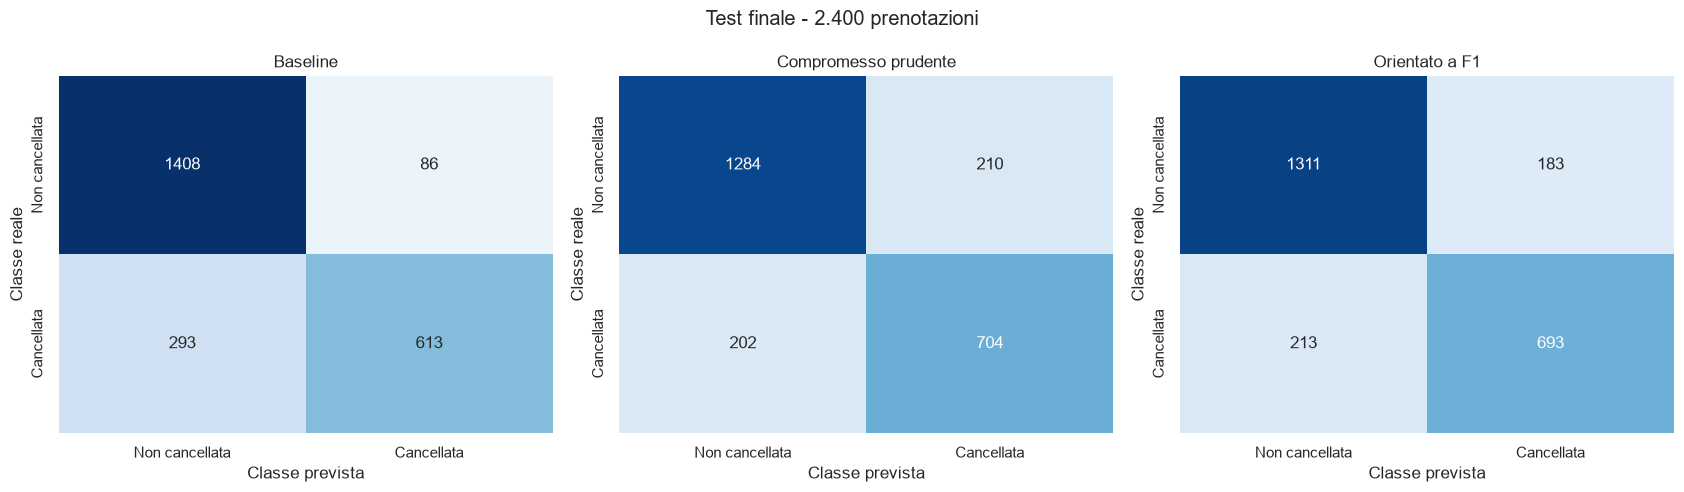

In [71]:
# DIVARIO TRAINING-TEST DEI MODELLI FINALI E MATRICI DI CONFUSIONE.
# Ogni F1 training viene misurato sul training COMPLETO con lo stesso modello usato sul test.
# Non lo sostituiamo con la media training dei fold: quella proviene da addestramenti su meno righe.
# Per il test riusiamo le previsioni già calcolate; non cambiamo alcuna decisione o parametro.
import matplotlib.pyplot as plt
import seaborn as sns

for nome_test_finale, pipeline_test_finale in modelli_test_finale.items():
    f1_training_completo_test = f1_score(
        y_train, pipeline_test_finale.predict(X_train), zero_division=0,
    )
    confronto_test_finale.loc[nome_test_finale, 'F1 training completo'] = f1_training_completo_test
    confronto_test_finale.loc[nome_test_finale, 'Gap F1 training-test (punti)'] = (
        f1_training_completo_test - confronto_test_finale.loc[nome_test_finale, 'F1 test']
    ) * 100

print('Stesso modello finale: training completo e test tenuto da parte.')
display(confronto_test_finale[[
    'F1 training completo', 'F1 CV (tre seed)', 'F1 test',
    'Gap F1 training-test (punti)', 'Accuracy test',
    'Precision test', 'Recall test', 'ROC AUC test',
]].round(4))

# Condividiamo scala dei colori e ordine delle classi, per confrontare le tre matrici.
# Diagonale: previsioni corrette. Alto-destra: falsi allarmi. Basso-sinistra: cancellazioni perse.
fig_matrici_test_finale, assi_matrici_test_finale = plt.subplots(1, 3, figsize=(17, 5))
massimo_matrici_test_finale = max(m.max() for m in matrici_test_finale.values())
for asse_test_finale, (nome_test_finale, matrice_test_finale) in zip(
    assi_matrici_test_finale, matrici_test_finale.items()
):
    sns.heatmap(
        matrice_test_finale, annot=True, fmt='d', cmap='Blues',
        vmin=0, vmax=massimo_matrici_test_finale, cbar=False,
        xticklabels=['Non cancellata', 'Cancellata'],
        yticklabels=['Non cancellata', 'Cancellata'],
        ax=asse_test_finale,
    )
    asse_test_finale.set_title(nome_test_finale)
    asse_test_finale.set_xlabel('Classe prevista')
    asse_test_finale.set_ylabel('Classe reale')
fig_matrici_test_finale.suptitle('Test finale - 2.400 prenotazioni')
plt.tight_layout()
plt.show()

## Esito del test finale

Sono stati valutati **2.400 casi**, con **906 prenotazioni cancellate** e **1.494 non cancellate**. Le righe sono separate per indice dal training di 9.600 casi; parametri, preprocessing e soglia di decisione erano già stati fissati. I due nuovi modelli erano già addestrati sul training completo. La baseline, già valutata nelle prime celle, è stata riprodotta con le stesse impostazioni.

### Risultati sul test

| Modello | F1 CV medio | F1 test | Accuracy | Precision cancellata | Recall cancellata | ROC AUC |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 0,7690 | 0,7639 | 0,8421 | 0,8770 | 0,6766 | 0,9236 |
| Compromesso prudente | 0,7871 | 0,7736 | 0,8283 | 0,7702 | 0,7770 | 0,9196 |
| Orientato a F1 | 0,7923 | 0,7778 | 0,8350 | 0,7911 | 0,7649 | 0,9233 |

Il compromesso prudente migliora F1 rispetto alla baseline di circa **0,98 punti** sul test. Il vantaggio è più piccolo di quello medio osservato in cross-validation. La variante orientata a F1 raggiunge il valore maggiore su questo campione; il confronto è descrittivo e non viene usato per cambiare la scelta o avviare un nuovo tuning.

### Che cosa cambia negli errori

| Modello | Cancellazioni trovate | Cancellazioni perse | Falsi allarmi | Non cancellate corrette |
|---|---:|---:|---:|---:|
| Baseline | 613 | 293 | 86 | 1.408 |
| Compromesso prudente | 704 | 202 | 210 | 1.284 |
| Orientato a F1 | 693 | 213 | 183 | 1.311 |

Rispetto alla baseline, il compromesso trova **91 cancellazioni in più**, ma produce **124 falsi allarmi in più**. Un falso allarme è una prenotazione non cancellata che il modello segnala come cancellata. Questo spiega il recall più alto e la precision più bassa. Accuracy e AUC non migliorano: il vantaggio riguarda l'obiettivo F1 della classe cancellata.

### Divario del modello finale fra training e test

Per questo calcolo è stato usato il training completo con lo stesso modello finale che ha prodotto le previsioni sul test. Non è stata sottratta al test la media training dei fold, che proviene da modelli addestrati su meno righe.

| Modello | F1 training completo | F1 test | Divario training-test |
|---|---:|---:|---:|
| Baseline | 0,8746 | 0,7639 | 11,07 punti |
| Compromesso prudente | 0,8406 | 0,7736 | 6,70 punti |
| Orientato a F1 | 0,8980 | 0,7778 | 12,02 punti |

Anche sul test il compromesso prudente presenta un divario inferiore alla baseline. Il modello orientato a F1 mantiene un divario maggiore: il suo F1 più alto non coincide con un minore sovradattamento su questo campione.

La proposta scelta prima del test resta `modello_rf_migliorato`, cioè il compromesso prudente. `modello_rf_miglior_f1` rimane un'alternativa con obiettivo differente. Nessun parametro o valore di soglia è stato modificato sulla base di queste metriche.

La tabella completa è disponibile in `confronto_test_finale`; previsioni e matrici sono in `predizioni_test_finale` e `matrici_test_finale`. Lo split è casuale sullo stesso dataset: la presenza di profili coincidenti e la generalizzazione a periodi successivi richiedono controlli distinti. Questo test è stato escluso dai recenti tuning, ma non va descritto come mai osservato in assoluto, perché le prime celle lo avevano già usato per la baseline.